# 🦺 Safety Helmet Detection Using YOLOv8
### AIRI Team PITB — AI Internship Task 1: End-to-End Computer Vision Project

| | |
|---|---|
| **Intern** | Hamza Nadeem |
| **Submitted to** | Omar Farooq — Associate AI/ML Engineer |
| **Task type** | Object detection (individual) |
| **Platform** | Google Colab (GPU) + Google Drive |
| **Model** | YOLOv8n baseline + YOLOv8s experiment (Ultralytics) |
| **Classes** | `helmet`, `no_helmet`, `person` |

This notebook implements **every phase** of the task brief, in order:

| Phase | What happens here |
|---|---|
| 6 | Colab setup — mount Drive, install Ultralytics, **GPU check** *(run first)* |
| 1 | Problem selection & use-case definition |
| 2 | Data collection — download, quality checks, **duplicate removal**, diversity-aware curation |
| 3 | Annotation — manual Roboflow batch (≥100 images), annotation import, **annotation audit** |
| 4 | Dataset organisation — 70/20/10 stratified split in YOLO format |
| 5 | `data.yaml` creation + explanation |
| 7 | Training — YOLOv8n baseline (≥30 epochs, 640px) + YOLOv8s experiment |
| 8 | Evaluation — Precision, Recall, mAP@0.5, mAP@0.5:0.95, confusion matrix, loss curves, per-class |
| 9 | Inference on unseen test images + video |
| 10 | Error analysis — automatic FP/FN/wrong-class/poor-box mining + manual review table |
| 11 | Demo — Gradio web app (and Streamlit app in `app/`) |
| — | Final report PDF, README results, LinkedIn post, deliverables checklist |

**How to run:** `Runtime → Change runtime type → T4 GPU`, then run cells top to bottom.
The only manual pause is **Phase 3** (annotating your batch in Roboflow) — see the instructions there.
Every output is written to Google Drive under `MyDrive/cv_project/`, so nothing is lost if the Colab session disconnects.

---
## ⚙️ Phase 6 — Google Colab Setup *(run first)*
Mount Google Drive so the dataset, trained weights and results persist, install Ultralytics, and confirm a GPU is attached.

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
!pip install -q -U ultralytics kagglehub imagehash fpdf2 tabulate

In [ ]:
import torch
print("GPU Available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU name     :", torch.cuda.get_device_name(0))
!nvidia-smi

GPU Available: True
GPU name     : Tesla T4
Sat Oct 17 21:31:23 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   40C    P8              9W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+---

In [ ]:
# ===================== PROJECT CONFIGURATION =====================
# Every tunable setting lives here so the whole project is reproducible from one place.
from pathlib import Path

PROJECT_TITLE = "Safety Helmet Detection Using YOLOv8"
AUTHOR        = "Hamza Nadeem"
SUPERVISOR    = "Omar Farooq - Associate AI/ML Engineer"

ROOT    = Path("/content/drive/MyDrive/cv_project")   # final project folder (Google Drive)
RAW_DIR = Path("/content/raw_data")                    # raw download (fast local Colab disk)

# ---- classes: list index = YOLO class id ----
CLASSES   = ["helmet", "no_helmet", "person"]
LABEL_MAP = {"helmet": "helmet", "head": "no_helmet", "person": "person"}   # source label -> our class

# ---- data curation ----
KAGGLE_DATASET    = "andrewmvd/hard-hat-detection"
SEED              = 42
TARGET_IMAGES     = 500        # brief: 150-300 minimum, 400+ = stronger submission
MANUAL_BATCH_SIZE = 120        # images annotated by hand in Roboflow (brief: at least 100)
SPLIT_RATIOS      = {"train": 0.70, "val": 0.20, "test": 0.10}
DEDUP_HAMMING     = 5          # perceptual-hash distance below which two images count as duplicates
MIN_BOX_PIXELS    = 4          # boxes thinner than this (px) are annotation noise and are dropped

# ---- training ----
EXPERIMENTS = [                # experiment 1 = required baseline; experiment 2 = stronger model
    {"name": "yolov8n_baseline", "weights": "yolov8n.pt", "epochs": 50, "batch": 16},
    {"name": "yolov8s_exp2",     "weights": "yolov8s.pt", "epochs": 50, "batch": 16},
]
RUN_EXPERIMENT_2 = True
IMGSZ   = 640
WORKERS = 2

# ---- inference / analysis ----
CONF_INFER    = 0.35           # confidence threshold for predictions (as in the brief)
IOU_MATCH     = 0.50           # IoU for a prediction to count as a correct match
IOU_POOR_BOX  = 0.30           # 0.30-0.50 IoU with the right class = "poor bounding box"
N_ERROR_CASES = 12             # brief: review at least 10

In [ ]:
# ===================== PATHS, FOLDERS, SHARED HELPERS =====================
import os, sys, json, time, random, shutil, glob, re, zipfile, math
import xml.etree.ElementTree as ET
from collections import Counter, defaultdict
import numpy as np, pandas as pd, cv2, yaml
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display, Markdown

random.seed(SEED); np.random.seed(SEED)
pd.set_option("display.max_colwidth", 80)

DATASET   = ROOT / "dataset"
DATA_YAML = DATASET / "data.yaml"
NOTEBOOKS = ROOT / "notebooks"
MODELS    = ROOT / "models"
REPORT    = ROOT / "report"
OUT       = ROOT / "outputs"
TRAIN_OUT = OUT / "training_results"
PRED_OUT  = OUT / "predictions"
DEMO_OUT  = OUT / "demo_results"
EVAL_OUT  = OUT / "evaluation"
ERR_OUT   = OUT / "error_analysis"
DATA_OUT  = OUT / "data_analysis"
MANUAL_DIR = ROOT / "manual_annotations"      # Roboflow batch to annotate + your export goes here
UNSEEN_DIR = ROOT / "unseen_images"           # optional: drop your own new photos here for Phase 9
VIDEO_DIR  = ROOT / "videos"                  # optional: drop a short .mp4 here for video inference
BEST_PT    = MODELS / "best.pt"
SUMMARY_JSON = OUT / "run_summary.json"

for split in ["train", "val", "test"]:
    (DATASET / "images" / split).mkdir(parents=True, exist_ok=True)
    (DATASET / "labels" / split).mkdir(parents=True, exist_ok=True)
for d in [NOTEBOOKS, MODELS, REPORT, TRAIN_OUT, PRED_OUT, DEMO_OUT, EVAL_OUT, ERR_OUT,
          DATA_OUT, MANUAL_DIR, UNSEEN_DIR, VIDEO_DIR, RAW_DIR]:
    d.mkdir(parents=True, exist_ok=True)

CLS2ID = {c: i for i, c in enumerate(CLASSES)}
COLORS = {"helmet": (46, 204, 113), "no_helmet": (231, 76, 60), "person": (52, 152, 219)}  # RGB

# ---- run summary: every phase stores its key numbers here (survives Colab restarts) ----
def load_summary():
    return json.loads(SUMMARY_JSON.read_text()) if SUMMARY_JSON.exists() else {}

def save_summary(key, value):
    s = load_summary(); s[key] = value
    SUMMARY_JSON.write_text(json.dumps(s, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o)))

# ---- geometry / label helpers ----
def iou_matrix(a, b):
    # IoU between every box in a (N,4) and b (M,4), boxes in x1,y1,x2,y2
    a, b = np.asarray(a, float).reshape(-1, 4), np.asarray(b, float).reshape(-1, 4)
    if len(a) == 0 or len(b) == 0:
        return np.zeros((len(a), len(b)))
    x1 = np.maximum(a[:, None, 0], b[None, :, 0]); y1 = np.maximum(a[:, None, 1], b[None, :, 1])
    x2 = np.minimum(a[:, None, 2], b[None, :, 2]); y2 = np.minimum(a[:, None, 3], b[None, :, 3])
    inter = np.clip(x2 - x1, 0, None) * np.clip(y2 - y1, 0, None)
    area_a = (a[:, 2] - a[:, 0]) * (a[:, 3] - a[:, 1]); area_b = (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1])
    return inter / (area_a[:, None] + area_b[None, :] - inter + 1e-9)

def read_yolo_label(path, w=1.0, h=1.0):
    # returns list of (cls_id, x1, y1, x2, y2) scaled by (w, h)
    out = []
    p = Path(path)
    if not p.exists():
        return out
    for line in p.read_text().strip().splitlines():
        parts = line.split()
        if len(parts) != 5:
            continue
        c, xc, yc, bw, bh = int(float(parts[0])), *map(float, parts[1:])
        out.append((c, (xc - bw / 2) * w, (yc - bh / 2) * h, (xc + bw / 2) * w, (yc + bh / 2) * h))
    return out

def draw_boxes(img_rgb, boxes, names=CLASSES, thickness=2, with_conf=False):
    # boxes: (cls, x1, y1, x2, y2[, conf]) in pixels
    img = img_rgb.copy()
    for b in boxes:
        c, x1, y1, x2, y2 = b[:5]
        name = names[int(c)]
        col = COLORS.get(name, (255, 255, 0))
        cv2.rectangle(img, (int(x1), int(y1)), (int(x2), int(y2)), col, thickness)
        label = f"{name} {b[5]:.2f}" if with_conf and len(b) > 5 else name
        cv2.putText(img, label, (int(x1), max(10, int(y1) - 3)), cv2.FONT_HERSHEY_SIMPLEX, 0.4, col, 1, cv2.LINE_AA)
    return img

def imread_rgb(path):
    img = cv2.imread(str(path))
    return None if img is None else cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

print("Project root:", ROOT)

Project root: /content/drive/MyDrive/cv_project


---
## 🎯 Phase 1 — Problem Selection

**Project:** Safety Helmet Detection (Option B of the brief).

| Question from the brief | Answer |
|---|---|
| **1. What objects will the system detect?** | Workers' heads **with** a safety helmet, heads **without** a helmet, and people. |
| **2. Why is this problem useful?** | Head injuries are among the most serious workplace accidents, and helmet rules are hard to enforce by manual watching. An automatic detector can scan camera footage continuously and flag violations the moment they happen. |
| **3. Where can it be applied?** | Construction sites, factories, warehouses, mines, oil & gas plants, and road safety for motorcyclists — anywhere CCTV already exists. |
| **4. Target classes** | `0: helmet`, `1: no_helmet`, `2: person` |
| **5. Final output** | For each image or video frame: bounding boxes with class labels and confidence scores, plus a **compliance status** — `VIOLATION` if any `no_helmet` is detected, otherwise `COMPLIANT`. |

> This project detects helmets and no-helmet cases in workplace safety images. The system supports basic safety monitoring by identifying people who are not wearing helmets and flagging the image as a safety violation.

**Design decision — why `no_helmet` is a head box, not a person box:** a helmet is judged at the head. Labelling the *bare head* (rather than the whole body) gives the model a small, well-defined visual target that is directly comparable to the `helmet` box, which makes the helmet / no-helmet decision far more reliable.

---
## 📥 Phase 2 — Data Collection

**Source chosen:** [Hard Hat Workers dataset — Kaggle (`andrewmvd/hard-hat-detection`)](https://www.kaggle.com/datasets/andrewmvd/hard-hat-detection), originally published by MakeML and also mirrored on Roboflow Universe (Northeastern University – China).

**Why this dataset (after comparing Roboflow Universe and Kaggle options):**
- **License: CC0 (public domain)** — legal to use, modify and publish in a portfolio.
- Its three source labels (`helmet`, `head`, `person`) map one-to-one onto the brief's Option B classes (`helmet`, `no_helmet`, `person`).
- 5,000 real workplace images with high variety: indoor/outdoor, crowds and single workers, close-ups and far-away people, different helmet colours, day and low-light scenes.
- Annotations ship in Pascal VOC XML — converting them to YOLO format ourselves demonstrates the full data-preparation workflow (instead of downloading a ready-made YOLO export).

**How the brief's collection rules are enforced in code:**

| Rule | Implementation |
|---|---|
| No duplicate images | Perceptual hashing (pHash) removes exact *and* near-duplicates |
| No long runs of consecutive video frames | Near-duplicate removal also catches consecutive frames |
| Different angles / backgrounds; easy & difficult examples | Every image is tagged (small objects, dark, blurry, crowded) and the curation guarantees a share of each |
| All classes represented | Curation enforces a minimum share of images containing `no_helmet` and `person` |
| Sources stated clearly | A `dataset_sources.csv` manifest records the origin and license of every image |

In [ ]:
# Download the dataset (≈ 1.2 GB). kagglehub works anonymously for public datasets;
# if it asks for credentials, upload your kaggle.json (Kaggle -> Settings -> Create New Token).
import kagglehub

def find_raw_root():
    xmls = list(RAW_DIR.rglob("*.xml"))
    return RAW_DIR if xmls else None

if find_raw_root() is None:
    try:
        src = kagglehub.dataset_download(KAGGLE_DATASET)
    except Exception as e:
        print("Anonymous download failed ->", e, "\nPlease upload kaggle.json")
        from google.colab import files
        up = files.upload()
        os.makedirs(os.path.expanduser("~/.kaggle"), exist_ok=True)
        shutil.copy(list(up.keys())[0], os.path.expanduser("~/.kaggle/kaggle.json"))
        os.chmod(os.path.expanduser("~/.kaggle/kaggle.json"), 0o600)
        src = kagglehub.dataset_download(KAGGLE_DATASET)
    shutil.copytree(src, RAW_DIR, dirs_exist_ok=True)

n_xml = len(list(RAW_DIR.rglob("*.xml")))
n_img = len([p for p in RAW_DIR.rglob("*") if p.suffix.lower() in (".png", ".jpg", ".jpeg")])
print(f"Raw dataset ready: {n_img} images, {n_xml} annotation files")

Raw dataset ready: 5000 images, 5000 annotation files


In [ ]:
# ---- Parse Pascal VOC XML annotations ----
IMG_EXT = (".png", ".jpg", ".jpeg", ".bmp")
img_index = {p.stem: p for p in RAW_DIR.rglob("*") if p.suffix.lower() in IMG_EXT}

records, box_rows, unknown_labels, missing_img = [], [], Counter(), 0
for xml_path in sorted(RAW_DIR.rglob("*.xml")):
    root = ET.parse(xml_path).getroot()
    stem = Path(root.findtext("filename") or xml_path.stem).stem
    img_path = img_index.get(stem) or img_index.get(xml_path.stem)
    if img_path is None:
        missing_img += 1
        continue
    for obj in root.findall("object"):
        name = (obj.findtext("name") or "").strip().lower()
        if name not in LABEL_MAP:
            unknown_labels[name] += 1
            continue
        bb = obj.find("bndbox")
        x1, y1, x2, y2 = (float(bb.findtext(k)) for k in ("xmin", "ymin", "xmax", "ymax"))
        box_rows.append(dict(stem=img_path.stem, cls=LABEL_MAP[name], x1=x1, y1=y1, x2=x2, y2=y2))
    records.append(dict(stem=img_path.stem, path=str(img_path)))

img_df = pd.DataFrame(records).drop_duplicates("stem").reset_index(drop=True)
box_df = pd.DataFrame(box_rows)
print(f"Images with annotations: {len(img_df)} | boxes: {len(box_df)} | xml without image: {missing_img}")
if unknown_labels:
    print("Ignored labels:", dict(unknown_labels))
print("\nRaw class distribution (boxes):")
print(box_df["cls"].value_counts().to_string())

Images with annotations: 5000 | boxes: 25502 | xml without image: 0

Raw class distribution (boxes):
cls
helmet       18966
no_helmet     5785
person         751


In [ ]:
# ---- Image quality features + perceptual hash (for de-duplication) ----
import imagehash
from concurrent.futures import ThreadPoolExecutor

def image_features(path):
    img = cv2.imread(path)
    if img is None:
        return None
    h, w = img.shape[:2]
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    return dict(w=w, h=h,
                brightness=float(gray.mean()),
                blur=float(cv2.Laplacian(gray, cv2.CV_64F).var()),
                phash=str(imagehash.phash(Image.fromarray(gray))))

with ThreadPoolExecutor(8) as ex:
    feats = list(ex.map(image_features, img_df["path"]))
bad = [i for i, f in enumerate(feats) if f is None]
img_df = img_df.drop(index=bad).reset_index(drop=True)
img_df = pd.concat([img_df, pd.DataFrame([f for f in feats if f is not None])], axis=1)
print(f"Readable images: {len(img_df)}  (unreadable/corrupt removed: {len(bad)})")

# ---- clean boxes: clip to image, drop degenerate / tiny boxes ----
box_df = box_df.merge(img_df[["stem", "w", "h"]], on="stem", how="inner")
box_df["x1"] = box_df["x1"].clip(0, box_df["w"]); box_df["x2"] = box_df["x2"].clip(0, box_df["w"])
box_df["y1"] = box_df["y1"].clip(0, box_df["h"]); box_df["y2"] = box_df["y2"].clip(0, box_df["h"])
bw, bh = box_df["x2"] - box_df["x1"], box_df["y2"] - box_df["y1"]
degenerate = (bw < MIN_BOX_PIXELS) | (bh < MIN_BOX_PIXELS)
print(f"Degenerate/tiny boxes removed: {int(degenerate.sum())}")
box_df = box_df[~degenerate].copy()
box_df["rel_area"] = ((box_df["x2"] - box_df["x1"]) * (box_df["y2"] - box_df["y1"])) / (box_df["w"] * box_df["h"])

# exact duplicate boxes (same class, IoU > 0.95) are annotation errors
dup_boxes = 0
keep_idx = []
for stem, g in box_df.groupby("stem"):
    kept = []
    for idx, r in g.iterrows():
        b = [r.x1, r.y1, r.x2, r.y2]
        if any(box_df.at[k, "cls"] == r.cls and iou_matrix([b], [[box_df.at[k, c] for c in ("x1", "y1", "x2", "y2")]])[0, 0] > 0.95 for k in kept):
            dup_boxes += 1
            continue
        kept.append(idx)
    keep_idx += kept
box_df = box_df.loc[keep_idx].reset_index(drop=True)
print(f"Duplicate boxes removed: {dup_boxes}")

Readable images: 5000  (unreadable/corrupt removed: 0)
Degenerate/tiny boxes removed: 11
Duplicate boxes removed: 0


Near-duplicates removed: 92  ->  4908 unique images remain


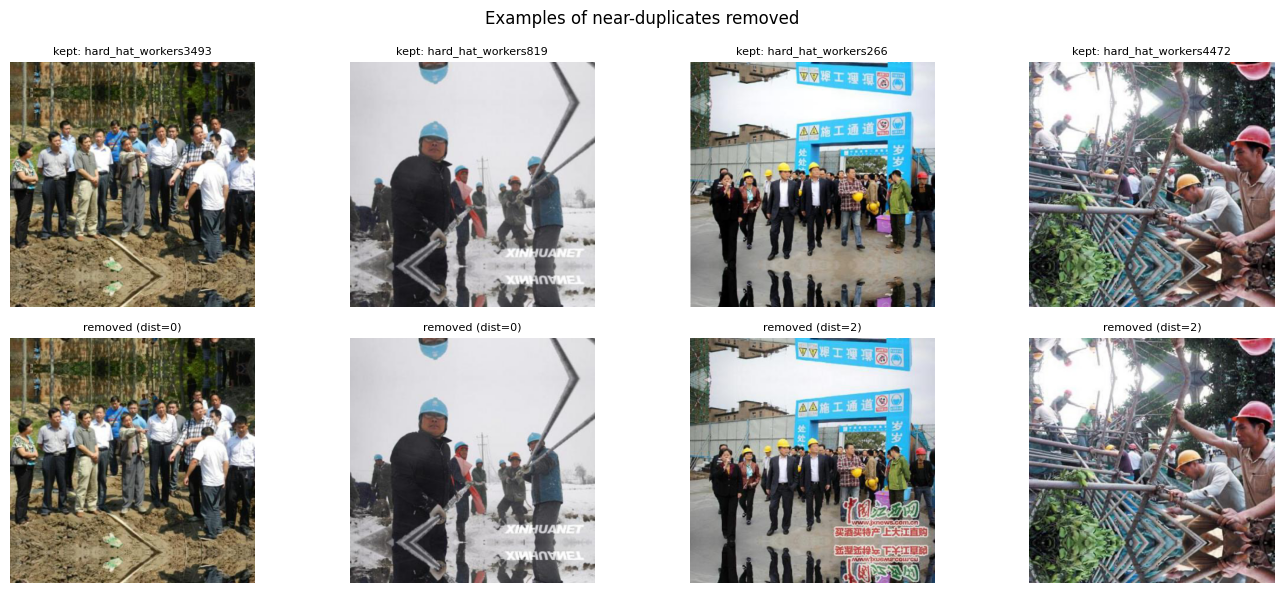

In [ ]:
# ---- Near-duplicate image removal with perceptual hashing ----
# pHash turns each image into a 64-bit fingerprint; images whose fingerprints differ in
# <= DEDUP_HAMMING bits look the same (re-encodes, resizes, consecutive video frames).
counts = box_df.groupby("stem").size()
img_df["n_boxes"] = img_df["stem"].map(counts).fillna(0).astype(int)
img_df = img_df[img_df["n_boxes"] > 0].sort_values("n_boxes", ascending=False).reset_index(drop=True)

hash_bytes = np.array([np.frombuffer(bytes.fromhex(h), dtype=np.uint8) for h in img_df["phash"]])
POPCOUNT = np.array([bin(i).count("1") for i in range(256)], dtype=np.uint8)
removed = np.zeros(len(img_df), bool)
dup_pairs = []
for i in range(len(img_df)):
    if removed[i]:
        continue
    dist = POPCOUNT[np.bitwise_xor(hash_bytes[i + 1:], hash_bytes[i])].sum(1)
    dups = np.where(dist <= DEDUP_HAMMING)[0] + i + 1
    for j in dups:
        if not removed[j]:
            removed[j] = True
            dup_pairs.append((img_df.at[i, "stem"], img_df.at[j, "stem"], int(dist[j - i - 1])))

n_before = len(img_df)
img_df = img_df[~removed].reset_index(drop=True)
box_df = box_df[box_df["stem"].isin(img_df["stem"])].reset_index(drop=True)
print(f"Near-duplicates removed: {n_before - len(img_df)}  ->  {len(img_df)} unique images remain")
pd.DataFrame(dup_pairs, columns=["kept", "removed_duplicate", "hamming"]).to_csv(DATA_OUT / "duplicates_removed.csv", index=False)

if dup_pairs:
    fig, axes = plt.subplots(2, min(4, len(dup_pairs)), figsize=(14, 6), squeeze=False)
    for k, (a, b, d) in enumerate(dup_pairs[:axes.shape[1]]):
        for r, s in enumerate((a, b)):
            axes[r, k].imshow(imread_rgb(img_df.set_index("stem").path.get(s, img_index[s]))); axes[r, k].axis("off")
        axes[0, k].set_title(f"kept: {a}", fontsize=8); axes[1, k].set_title(f"removed (dist={d})", fontsize=8)
    plt.suptitle("Examples of near-duplicates removed"); plt.tight_layout()
    plt.savefig(DATA_OUT / "duplicate_examples.png", dpi=110); plt.show()

,value
images selected,500
boxes: helmet,1737
boxes: no_helmet,1533
boxes: person,751
images containing helmet,380
images containing no_helmet,270
images containing person,158
images tagged small,233
images tagged dark,78
images tagged blurry,100


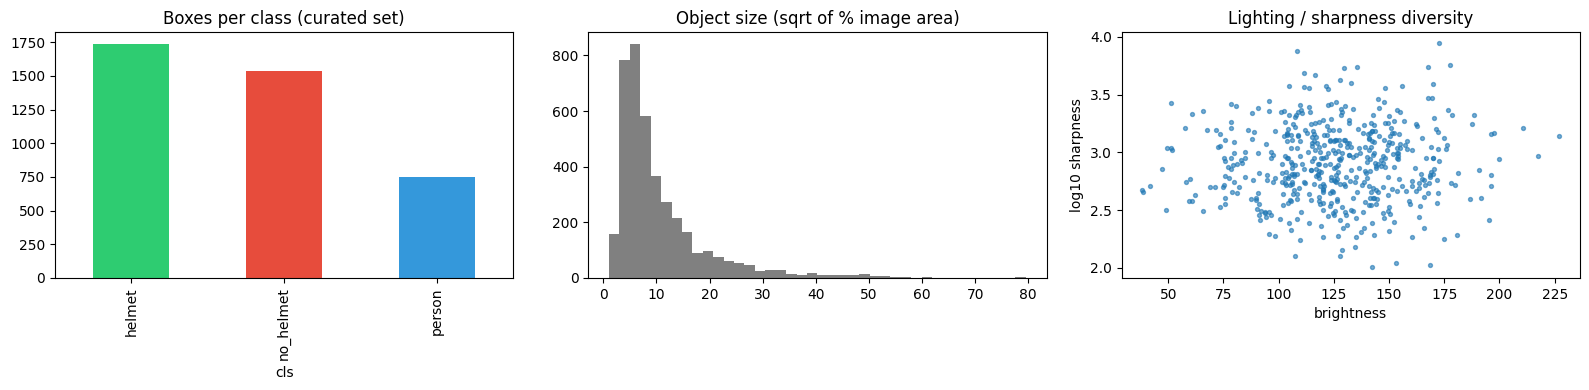

In [ ]:
# ---- Diversity-aware curation of the final image set ----
# Goal: a manageable dataset (TARGET_IMAGES) that still covers every class and every
# difficulty condition, instead of a random sample dominated by easy helmet images.
per_img = box_df.pivot_table(index="stem", columns="cls", values="x1", aggfunc="count", fill_value=0)
for c in CLASSES:
    if c not in per_img:
        per_img[c] = 0
img_df = img_df.merge(per_img[CLASSES].reset_index(), on="stem", how="left").fillna(0)
min_area = box_df.groupby("stem")["rel_area"].min()
img_df["min_rel_area"] = img_df["stem"].map(min_area)

# difficulty tags (thresholds = lower quantiles of THIS dataset, so they adapt automatically)
dark_t, blur_t = img_df["brightness"].quantile(0.15), img_df["blur"].quantile(0.15)
img_df["tag_small"]   = img_df["min_rel_area"] < 0.0025      # object < 0.25% of the image
img_df["tag_dark"]    = img_df["brightness"] < dark_t
img_df["tag_blurry"]  = img_df["blur"] < blur_t
img_df["tag_crowded"] = img_df["n_boxes"] >= 8
img_df["tag_easy"]    = ~(img_df[["tag_small", "tag_dark", "tag_blurry", "tag_crowded"]].any(axis=1))

rng = np.random.default_rng(SEED)
selected = []
def take(mask, n):
    pool = img_df[mask & ~img_df["stem"].isin(selected)]["stem"].tolist()
    rng.shuffle(pool)
    selected.extend(pool[:max(0, n)])

N = min(TARGET_IMAGES, len(img_df))
take(img_df["person"] > 0, int(0.35 * N))                     # rare class first
need_nh = int(0.50 * N) - int(img_df[img_df.stem.isin(selected)]["no_helmet"].gt(0).sum())
take(img_df["no_helmet"] > 0, need_nh)                         # at least half the images contain a violation
for tag in ["tag_small", "tag_dark", "tag_blurry", "tag_crowded"]:
    need = int(0.12 * N) - int(img_df[img_df.stem.isin(selected)][tag].sum())
    take(img_df[tag], need)                                    # >= 12% of images per difficulty condition
take(img_df["tag_easy"], int(0.15 * N) - int(img_df[img_df.stem.isin(selected)]["tag_easy"].sum()))
take(pd.Series(True, index=img_df.index), N - len(selected))   # fill the rest at random
selected = selected[:N]

sel_df = img_df[img_df["stem"].isin(selected)].reset_index(drop=True)
sel_box = box_df[box_df["stem"].isin(selected)].reset_index(drop=True)

summary_rows = {
    "images selected": len(sel_df),
    **{f"boxes: {c}": int((sel_box.cls == c).sum()) for c in CLASSES},
    **{f"images containing {c}": int((sel_df[c] > 0).sum()) for c in CLASSES},
    **{k.replace("tag_", "images tagged "): int(sel_df[k].sum()) for k in ["tag_small", "tag_dark", "tag_blurry", "tag_crowded", "tag_easy"]},
}
display(pd.Series(summary_rows, name="value").to_frame())

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sel_box["cls"].value_counts().reindex(CLASSES).plot.bar(ax=ax[0], color=[np.array(COLORS[c]) / 255 for c in CLASSES])
ax[0].set_title("Boxes per class (curated set)")
ax[1].hist(np.sqrt(sel_box["rel_area"]) * 100, bins=40, color="gray"); ax[1].set_title("Object size (sqrt of % image area)")
ax[2].scatter(sel_df["brightness"], np.log10(sel_df["blur"] + 1), s=8, alpha=.6)
ax[2].set_xlabel("brightness"); ax[2].set_ylabel("log10 sharpness"); ax[2].set_title("Lighting / sharpness diversity")
plt.tight_layout(); plt.savefig(DATA_OUT / "dataset_diversity.png", dpi=110); plt.show()

save_summary("data_collection", dict(
    source=f"Kaggle: {KAGGLE_DATASET} (Hard Hat Workers, MakeML) - CC0 public domain",
    raw_images=int(n_before + 0), unique_after_dedup=int(len(img_df)), duplicates_removed=int(n_before - len(img_df)),
    degenerate_boxes_removed=int(degenerate.sum()), duplicate_boxes_removed=int(dup_boxes), **summary_rows))

In [ ]:
# ---- Source manifest (brief: "mention dataset sources clearly") ----
manifest = sel_df[["stem", "w", "h", "brightness", "blur"] + CLASSES].copy()
manifest["source"] = "Kaggle andrewmvd/hard-hat-detection (MakeML Hard Hat Workers)"
manifest["license"] = "CC0 1.0 (public domain)"
manifest.to_csv(DATA_OUT / "dataset_sources.csv", index=False)
print("Saved", DATA_OUT / "dataset_sources.csv")

# preview a mix of easy and difficult images with the original labels
show = pd.concat([sel_df[sel_df[t]].sample(min(2, int(sel_df[t].sum())), random_state=SEED)
                  for t in ["tag_easy", "tag_small", "tag_dark", "tag_blurry", "tag_crowded"] if sel_df[t].sum()])
fig, axes = plt.subplots(2, 5, figsize=(20, 8))
for ax, (_, r) in zip(axes.flat, show.iterrows()):
    bx = [(CLS2ID[b.cls], b.x1, b.y1, b.x2, b.y2) for b in sel_box[sel_box.stem == r.stem].itertuples()]
    ax.imshow(draw_boxes(imread_rgb(r.path), bx))
    tags = [t[4:] for t in ["tag_easy", "tag_small", "tag_dark", "tag_blurry", "tag_crowded"] if r[t]]
    ax.set_title(f"{r.stem}\n{', '.join(tags)}", fontsize=8); ax.axis("off")
for ax in axes.flat[len(show):]:
    ax.axis("off")
plt.tight_layout(); plt.savefig(DATA_OUT / "sample_images.png", dpi=110); plt.show()

Output hidden; open in https://colab.research.google.com to view.

---
## ✏️ Phase 3 — Data Annotation (Roboflow Annotate)

The brief requires **at least 100 images annotated manually**. The workflow below makes that verifiable:

1. **Run the next cell.** It copies a stratified batch of `MANUAL_BATCH_SIZE` (120) curated images — **images only, no labels** — to `MyDrive/cv_project/manual_annotations/manual_batch.zip`.
2. Go to [roboflow.com](https://roboflow.com) → *Create New Project* → **Object Detection**, name it `safety-helmet-detection`.
3. Upload the images from `manual_batch.zip`. Create exactly these classes: **`helmet`, `no_helmet`, `person`**.
4. Annotate every image following the guidelines below (≈ 2–3 hours for 120 images). You may also add your **own photos** (self-captured) — they are imported automatically.
5. *Generate* a version with **no preprocessing resize and no augmentation** (Auto-Orient only), then *Export → Format: YOLOv8 → Download zip*.
6. Save the zip to Drive as **`MyDrive/cv_project/manual_annotations/roboflow_export.zip`** and continue running the notebook.

If the export is not there yet, the notebook continues with the reviewed public labels and prints a warning — so you can test the whole pipeline first and re-run from the import cell once your annotations are done.

**Annotation guidelines followed (from the brief):**
1. Tight boxes — edges touch the outermost visible pixels of the object.
2. Every visible helmet / bare head / person is labelled — no object left unlabelled.
3. One box per object — never one box around a group.
4. No excess background inside boxes.
5. Unclear objects are **not** guessed — if you cannot tell whether a head wears a helmet, skip it.
6. Partially visible objects are labelled only when the class is clearly identifiable.
7. Consistent class names: `helmet` = box around the helmet worn on the head; `no_helmet` = box around a bare head (caps, hoods, hair and scarves all count as `no_helmet`); `person` = full visible body.
8. Every image is reviewed a second time before export.

The import cell then **audits** your labels against the original public labels (agreement per class and box tightness) — this is the evidence of annotation quality for the report.

In [ ]:
# ---- Prepare the manual-annotation batch (stratified: covers all classes and difficulties) ----
manual_pool = sel_df.copy()
manual_pool["strata"] = (manual_pool["no_helmet"] > 0).astype(int).astype(str) + (manual_pool["person"] > 0).astype(int).astype(str) \
    + (~manual_pool["tag_easy"]).astype(int).astype(str)
n_manual = min(MANUAL_BATCH_SIZE, len(manual_pool))
manual_stems = (manual_pool.groupby("strata", group_keys=False)
                .apply(lambda g: g.sample(max(1, round(n_manual * len(g) / len(manual_pool))), random_state=SEED))
                ["stem"].tolist())
extra = manual_pool[~manual_pool.stem.isin(manual_stems)].sample(max(0, n_manual - len(manual_stems)), random_state=SEED)
manual_stems = (manual_stems + extra["stem"].tolist())[:n_manual]

batch_zip = MANUAL_DIR / "manual_batch.zip"
with zipfile.ZipFile(batch_zip, "w") as zf:
    for s in manual_stems:
        p = Path(sel_df.set_index("stem").at[s, "path"])
        zf.write(p, arcname=p.name)
(MANUAL_DIR / "manual_batch_list.txt").write_text("\n".join(manual_stems))
print(f"{len(manual_stems)} images ready for manual annotation -> {batch_zip}")

/tmp/ipykernel_476/519446079.py:7: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.sample(max(1, round(n_manual * len(g) / len(manual_pool))), random_state=SEED))


120 images ready for manual annotation -> /content/drive/MyDrive/cv_project/manual_annotations/manual_batch.zip


In [ ]:
# ---- Import my Roboflow annotations (YOLOv8 export) and audit them ----
EXPORT_ZIP = MANUAL_DIR / "roboflow_export.zip"
EXPORT_DIR = MANUAL_DIR / "roboflow_export"
SYNONYMS = {"head": "no_helmet", "no-helmet": "no_helmet", "no helmet": "no_helmet", "nohelmet": "no_helmet",
            "without_helmet": "no_helmet", "hardhat": "helmet", "hard_hat": "helmet", "hard-hat": "helmet",
            "with_helmet": "helmet", "worker": "person", "people": "person"}

def norm_name(n):
    n = str(n).strip().lower()
    return SYNONYMS.get(n, n.replace("-", "_").replace(" ", "_"))

def original_stem(roboflow_stem):
    # Roboflow renames 'hard_hat_workers12.png' to 'hard_hat_workers12_png.rf.<hash>.jpg'
    m = re.match(r"^(.*)_(png|jpg|jpeg|bmp)\.rf\.[0-9a-zA-Z]+$", roboflow_stem)
    return m.group(1) if m else roboflow_stem.split(".rf.")[0]

manual_labels = {}       # stem -> dict(image=path, boxes=[(cls_id, xc, yc, w, h)])
if EXPORT_ZIP.exists() and not EXPORT_DIR.exists():
    with zipfile.ZipFile(EXPORT_ZIP) as zf:
        zf.extractall(EXPORT_DIR)

if EXPORT_DIR.exists():
    yaml_files = list(EXPORT_DIR.rglob("data.yaml"))
    names = yaml.safe_load(yaml_files[0].read_text())["names"] if yaml_files else CLASSES
    names = list(names.values()) if isinstance(names, dict) else list(names)
    remap = {i: CLS2ID.get(norm_name(n)) for i, n in enumerate(names)}
    print("Roboflow class mapping:", {names[i]: (CLASSES[j] if j is not None else "IGNORED") for i, j in remap.items()})
    for img_p in EXPORT_DIR.rglob("*"):
        if img_p.suffix.lower() not in IMG_EXT or "images" not in img_p.parts:
            continue
        lbl_p = Path(str(img_p.parent).replace("images", "labels")) / (img_p.stem + ".txt")
        boxes = []
        for line in (lbl_p.read_text().splitlines() if lbl_p.exists() else []):
            parts = line.split()
            if len(parts) == 5 and remap.get(int(parts[0])) is not None:
                boxes.append((remap[int(parts[0])], *map(float, parts[1:])))
        manual_labels[original_stem(img_p.stem)] = dict(image=str(img_p), boxes=boxes)

MANUAL_DONE = len(manual_labels) >= 100
if not manual_labels:
    print("⚠️  No Roboflow export found yet at", EXPORT_ZIP)
    print("    Continuing with the reviewed public labels. Annotate the batch (see instructions above), "
          "upload the export, then re-run from this cell.")
else:
    n_new = sum(s not in set(sel_df.stem) for s in manual_labels)
    print(f"Imported {len(manual_labels)} manually annotated images "
          f"({len(manual_labels) - n_new} from the batch, {n_new} new self-collected images)")
    if not MANUAL_DONE:
        print("⚠️  Fewer than 100 manually annotated images - the brief requires at least 100.")

# ---- Annotation audit: my labels vs. the original public labels on the same images ----
audit_rows = []
for stem, m in manual_labels.items():
    if stem not in set(sel_df.stem):
        continue
    W, H = 1.0, 1.0   # compare in normalised coordinates
    mine = [(c, xc - w / 2, yc - h / 2, xc + w / 2, yc + h / 2) for c, xc, yc, w, h in m["boxes"]]
    r = sel_df.set_index("stem").loc[stem]
    orig = [(CLS2ID[b.cls], b.x1 / r.w, b.y1 / r.h, b.x2 / r.w, b.y2 / r.h) for b in sel_box[sel_box.stem == stem].itertuples()]
    for c in range(len(CLASSES)):
        a = [b[1:] for b in mine if b[0] == c]; o = [b[1:] for b in orig if b[0] == c]
        ious = iou_matrix(a, o); matched = []
        while ious.size and ious.max() >= 0.5:
            i, j = np.unravel_index(ious.argmax(), ious.shape); matched.append(ious[i, j]); ious[i, :] = 0; ious[:, j] = 0
        audit_rows.append(dict(cls=CLASSES[c], mine=len(a), original=len(o), matched=len(matched), iou_sum=float(np.sum(matched))))

if audit_rows:
    audit = pd.DataFrame(audit_rows).groupby("cls").sum().reindex(CLASSES)
    audit["agreement_vs_original_%"] = (100 * audit["matched"] / audit["original"].clip(lower=1)).round(1)
    audit["my_extra_boxes"] = (audit["mine"] - audit["matched"]).clip(lower=0)
    audit["mean_IoU_of_matches"] = (audit["iou_sum"] / audit["matched"].clip(lower=1)).round(3)
    audit = audit.drop(columns="iou_sum")
    display(audit)
    print("my_extra_boxes = objects I labelled that the public dataset had missed (often unlabelled people).")
    audit.to_csv(DATA_OUT / "annotation_audit.csv")
    save_summary("annotation_audit", audit.reset_index().to_dict("records"))
save_summary("annotation", dict(tool="Roboflow Annotate", manual_images=len(manual_labels),
                                manual_batch_prepared=len(manual_stems), manual_done=bool(MANUAL_DONE)))

⚠️  No Roboflow export found yet at /content/drive/MyDrive/cv_project/manual_annotations/roboflow_export.zip
    Continuing with the reviewed public labels. Annotate the batch (see instructions above), upload the export, then re-run from this cell.


---
## 🗂️ Phase 4 — Dataset Organisation (YOLO format, 70 / 20 / 10)

Each image gets a `.txt` file with one line per object: `<class_id> <x_center> <y_center> <width> <height>`, all normalised to 0–1.
The split is **stratified** (by whether the image contains `no_helmet`, `person`, is a difficult case, and was hand-annotated) so that validation and test sets have the same mix as training, and every image appears in exactly one split (no leakage).

In [ ]:
# ---- Build the final dataset: manual labels override public labels ----
final_items = []    # dict(stem, src_image, lines, manual)
for r in sel_df.itertuples():
    if r.stem in manual_labels:
        m = manual_labels[r.stem]
        lines = [f"{c} {xc:.6f} {yc:.6f} {w:.6f} {h:.6f}" for c, xc, yc, w, h in m["boxes"]]
        final_items.append(dict(stem=r.stem, src=m["image"], lines=lines, manual=True))
    else:
        lines = []
        for b in sel_box[sel_box.stem == r.stem].itertuples():
            xc, yc = (b.x1 + b.x2) / 2 / r.w, (b.y1 + b.y2) / 2 / r.h
            bw_, bh_ = (b.x2 - b.x1) / r.w, (b.y2 - b.y1) / r.h
            lines.append(f"{CLS2ID[b.cls]} {xc:.6f} {yc:.6f} {bw_:.6f} {bh_:.6f}")
        final_items.append(dict(stem=r.stem, src=r.path, lines=lines, manual=False))
for stem, m in manual_labels.items():          # brand-new self-collected images from Roboflow
    if stem not in set(sel_df.stem):
        lines = [f"{c} {xc:.6f} {yc:.6f} {w:.6f} {h:.6f}" for c, xc, yc, w, h in m["boxes"]]
        final_items.append(dict(stem=stem, src=m["image"], lines=lines, manual=True))

# ---- stratified 70/20/10 split ----
def strata_key(it):
    cls_ids = {int(l.split()[0]) for l in it["lines"]}
    hard = it["stem"] in set(sel_df[~sel_df.tag_easy].stem)
    return f"{int(1 in cls_ids)}{int(2 in cls_ids)}{int(hard)}{int(it['manual'])}"

groups = defaultdict(list)
for it in final_items:
    groups[strata_key(it)].append(it)
rng = np.random.default_rng(SEED)
for key, items in groups.items():
    rng.shuffle(items)
    n = len(items); n_test = round(n * SPLIT_RATIOS["test"]); n_val = round(n * SPLIT_RATIOS["val"])
    for k, it in enumerate(items):
        it["split"] = "test" if k < n_test else "val" if k < n_test + n_val else "train"

# ---- write images (JPEG q95 keeps the repo small) + labels; start from a clean folder ----
for split in ["train", "val", "test"]:
    for kind in ["images", "labels"]:
        d = DATASET / kind / split
        shutil.rmtree(d, ignore_errors=True); d.mkdir(parents=True)
for it in final_items:
    img = cv2.imread(it["src"])
    cv2.imwrite(str(DATASET / "images" / it["split"] / f"{it['stem']}.jpg"), img, [cv2.IMWRITE_JPEG_QUALITY, 95])
    (DATASET / "labels" / it["split"] / f"{it['stem']}.txt").write_text("\n".join(it["lines"]) + ("\n" if it["lines"] else ""))

split_df = pd.DataFrame([dict(stem=it["stem"], split=it["split"], manual=it["manual"], n_boxes=len(it["lines"]),
                              **{c: sum(int(l.split()[0]) == i for l in it["lines"]) for i, c in enumerate(CLASSES)})
                         for it in final_items])
split_df.to_csv(DATA_OUT / "split_assignment.csv", index=False)
split_table = split_df.groupby("split").agg(images=("stem", "count"), manual_images=("manual", "sum"),
                                            **{c: (c, "sum") for c in CLASSES}).reindex(["train", "val", "test"])
split_table["% of images"] = (100 * split_table["images"] / split_table["images"].sum()).round(1)
display(split_table)
save_summary("split", split_table.reset_index().to_dict("records"))

,images,manual_images,helmet,no_helmet,person,% of images
split,,,,,,
train,349,0,1183,1034,525,69.8
val,100,0,326,326,127,20.0
test,51,0,228,173,99,10.2


In [ ]:
# ---- Verify structure + validate every label file ----
def tree(d, prefix="", depth=0, max_depth=3):
    items = sorted([p for p in d.iterdir()], key=lambda p: (p.is_file(), p.name))
    dirs = [p for p in items if p.is_dir()]; files = [p for p in items if p.is_file()]
    for p in dirs:
        n = len(list(p.glob("*")))
        print(f"{prefix}├── {p.name}/" + (f"  ({n} files)" if depth == max_depth - 1 or not any(q.is_dir() for q in p.iterdir()) else ""))
        if depth < max_depth - 1 and any(q.is_dir() for q in p.iterdir()):
            tree(p, prefix + "│   ", depth + 1, max_depth)
    for p in files[:5]:
        print(f"{prefix}├── {p.name}")

print("dataset/"); tree(DATASET)

issues = Counter()
for split in ["train", "val", "test"]:
    imgs = {p.stem for p in (DATASET / "images" / split).glob("*.jpg")}
    lbls = {p.stem for p in (DATASET / "labels" / split).glob("*.txt")}
    issues["image without label"] += len(imgs - lbls); issues["label without image"] += len(lbls - imgs)
    for lp in (DATASET / "labels" / split).glob("*.txt"):
        for line in lp.read_text().split("\n"):
            if not line.strip():
                continue
            p = line.split()
            if len(p) != 5:
                issues["malformed line"] += 1; continue
            c, vals = int(p[0]), list(map(float, p[1:]))
            if c not in range(len(CLASSES)): issues["bad class id"] += 1
            if not all(0 <= v <= 1 for v in vals): issues["coordinate outside 0-1"] += 1
            if vals[2] <= 0 or vals[3] <= 0: issues["zero-size box"] += 1
all_stems = split_df["stem"]
issues["image in more than one split"] = int(all_stems.duplicated().sum())
print("\nLabel validation:", {k: v for k, v in issues.items()} or "no problems found ✅")
assert sum(issues.values()) == 0, "Fix the label problems above before training"
print("✅ All label files valid: normalised coordinates, valid class ids, one split per image")

# visual check of final YOLO labels (read back from disk = proves the conversion is correct)
sample = list((DATASET / "images" / "train").glob("*.jpg"))
random.Random(SEED).shuffle(sample)
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
for ax, ip in zip(axes.flat, sample[:8]):
    img = imread_rgb(ip); h, w = img.shape[:2]
    ax.imshow(draw_boxes(img, read_yolo_label(DATASET / "labels" / "train" / f"{ip.stem}.txt", w, h)))
    ax.set_title(ip.name + ("  [manual]" if ip.stem in manual_labels else ""), fontsize=8); ax.axis("off")
plt.suptitle("YOLO labels read back from disk  (green = helmet, red = no_helmet, blue = person)")
plt.tight_layout(); plt.savefig(DATA_OUT / "yolo_label_check.png", dpi=110); plt.show()

Output hidden; open in https://colab.research.google.com to view.

---
## 📄 Phase 5 — Dataset Configuration (`data.yaml`)

In [ ]:
data_cfg = {
    "path": str(DATASET),
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "names": {i: c for i, c in enumerate(CLASSES)},
}
DATA_YAML.write_text(yaml.safe_dump(data_cfg, sort_keys=False))
print(DATA_YAML.read_text())

path: /content/drive/MyDrive/cv_project/dataset
train: images/train
val: images/val
test: images/test
names:
  0: helmet
  1: no_helmet
  2: person



**What each field means:**

| Key | Meaning |
|---|---|
| `path` | Dataset root folder. Every other path in the file is relative to it. |
| `train` | Folder of training images. YOLO automatically finds each image's labels by swapping `images/` → `labels/` in the path. |
| `val` | Validation images — evaluated after every epoch to track progress and choose the best checkpoint (`best.pt`). Never used for weight updates. |
| `test` | Held-out test images — used **only once**, after training, to report final unbiased performance. |
| `names` | Mapping from class id (the first number in every label line) to class name. Its order must match the ids used in the label files. |

---
## 🏋️ Phase 7 — Model Training

Transfer learning from COCO-pretrained weights. **Experiment 1** is the required YOLOv8n baseline (640 px, 50 epochs ≥ 30 required). **Experiment 2** trains the larger YOLOv8s with the same data and settings to measure what extra model capacity buys — the brief lists multiple experiments as a mark of a stronger submission. The best model on the **validation** set becomes `models/best.pt` (the test set is not used for model selection).

Training saves every output (weights, `results.csv`, curves, confusion matrices, sample batches) to `outputs/training_results/<experiment>/` on Drive.

In [ ]:
from ultralytics import YOLO
import torch, ultralytics

DEVICE = 0 if torch.cuda.is_available() else "cpu"
GPU_NAME = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU (no GPU)"
print("Ultralytics", ultralytics.__version__, "| device:", GPU_NAME)

def train_experiment(exp):
    model = YOLO(exp["weights"])
    t0 = time.time()
    model.train(
        data=str(DATA_YAML), epochs=exp["epochs"], imgsz=IMGSZ, batch=exp["batch"], pretrained=True,
        project=str(TRAIN_OUT), name=exp["name"], exist_ok=True,
        patience=exp["epochs"],      # no early stop: always completes the full schedule (>= 30 epochs)
        seed=SEED, deterministic=True, workers=WORKERS, device=DEVICE, plots=True, verbose=False,
    )
    minutes = (time.time() - t0) / 60
    run_dir = Path(model.trainer.save_dir)
    res = pd.read_csv(run_dir / "results.csv"); res.columns = [c.strip() for c in res.columns]
    best_row = res.loc[res["metrics/mAP50-95(B)"].idxmax()]
    info = dict(name=exp["name"], weights=exp["weights"], epochs=exp["epochs"], imgsz=IMGSZ, batch=exp["batch"],
                optimizer=str(model.trainer.args.optimizer), lr0=float(model.trainer.args.lr0),
                gpu=GPU_NAME, train_minutes=round(minutes, 1), run_dir=str(run_dir),
                best_pt=str(model.trainer.best), best_epoch=int(best_row["epoch"]),
                val_mAP50=round(float(best_row["metrics/mAP50(B)"]), 4),
                val_mAP50_95=round(float(best_row["metrics/mAP50-95(B)"]), 4))
    (run_dir / "run_info.json").write_text(json.dumps(info, indent=2))
    print(f"✅ {exp['name']}: {minutes:.1f} min on {GPU_NAME} | best epoch {info['best_epoch']} | "
          f"val mAP50 {info['val_mAP50']:.3f} | val mAP50-95 {info['val_mAP50_95']:.3f}")
    return info

experiment_results = [train_experiment(EXPERIMENTS[0])]

Ultralytics 8.4.181 | device: Tesla T4
Ultralytics 8.4.181 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/cv_project/dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name

In [ ]:
# Experiment 2: YOLOv8s (same data/settings)
if RUN_EXPERIMENT_2 and len(EXPERIMENTS) > 1:
    experiment_results.append(train_experiment(EXPERIMENTS[1]))

Ultralytics 8.4.181 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/cv_project/dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8s_exp2, nbs=64, nms=None, opset=

In [ ]:
# ---- Compare experiments and promote the best (selected on VALIDATION mAP50-95) ----
exp_df = pd.DataFrame(experiment_results).set_index("name")
display(exp_df[["weights", "epochs", "imgsz", "batch", "optimizer", "gpu", "train_minutes", "best_epoch", "val_mAP50", "val_mAP50_95"]])
best_exp = exp_df["val_mAP50_95"].idxmax()
shutil.copy(exp_df.at[best_exp, "best_pt"], BEST_PT)
for name, row in exp_df.iterrows():
    shutil.copy(row["best_pt"], MODELS / f"{name}_best.pt")
print(f"🏆 Best experiment: {best_exp} -> copied to {BEST_PT}")
save_summary("training", dict(experiments=exp_df.reset_index().to_dict("records"), best_experiment=best_exp))

,weights,epochs,imgsz,batch,optimizer,gpu,train_minutes,best_epoch,val_mAP50,val_mAP50_95
name,,,,,,,,,,
yolov8n_baseline,yolov8n.pt,50,640,16,AdamW,Tesla T4,6.9,49,0.7171,0.4547
yolov8s_exp2,yolov8s.pt,50,640,16,AdamW,Tesla T4,6.5,47,0.7221,0.4512


🏆 Best experiment: yolov8n_baseline -> copied to /content/drive/MyDrive/cv_project/models/best.pt


---
## 📊 Phase 8 — Model Evaluation

**What the metrics mean**

- **Precision** = TP / (TP + FP) — *of all the boxes the model drew, how many were correct?* High precision = few false alarms (e.g. not flagging a worker who **is** wearing a helmet).
- **Recall** = TP / (TP + FN) — *of all the real objects, how many did the model find?* High recall = few misses. For safety monitoring, recall on `no_helmet` matters most: a missed violation is worse than a false alarm.
- **IoU (Intersection over Union)** — overlap between a predicted box and the true box. A prediction counts as correct only if IoU ≥ the threshold *and* the class is right.
- **AP (Average Precision)** — area under the precision–recall curve for one class, i.e. precision averaged over all recall levels as the confidence threshold sweeps from high to low.
- **mAP@0.5** — AP averaged over all classes with IoU threshold 0.5 (*"did it find the object in roughly the right place?"*).
- **mAP@0.5:0.95** — AP averaged over IoU thresholds 0.50, 0.55, …, 0.95 — rewards **tight**, precisely placed boxes. It is the stricter COCO metric and always lower than mAP@0.5.
- **Confusion matrix** — rows = predicted class, columns = true class; the extra *background* row/column counts false positives (predicted but not real) and false negatives (real but missed).

In [ ]:
best_model = YOLO(str(BEST_PT))

def evaluate(split):
    m = best_model.val(data=str(DATA_YAML), split=split, imgsz=IMGSZ, batch=16, device=DEVICE, plots=True,
                       project=str(EVAL_OUT), name=split, exist_ok=True, verbose=False)
    overall = dict(split=split, precision=m.box.mp, recall=m.box.mr, mAP50=m.box.map50, mAP50_95=m.box.map)
    labels_dir = DATASET / "labels" / split
    inst = Counter(int(l.split()[0]) for p in labels_dir.glob("*.txt") for l in p.read_text().splitlines() if l.strip())
    rows = []
    for i, c in enumerate(m.box.ap_class_index):
        rows.append(dict(split=split, cls=m.names[int(c)], instances=inst.get(int(c), 0), precision=m.box.p[i],
                         recall=m.box.r[i], mAP50=m.box.ap50[i], mAP50_95=m.box.ap[i]))
    return m, overall, pd.DataFrame(rows)

val_m, val_overall, val_cls = evaluate("val")
test_m, test_overall, test_cls = evaluate("test")

overall_df = pd.DataFrame([val_overall, test_overall]).set_index("split").round(4)
per_class_df = pd.concat([val_cls, test_cls]).round(4)
display(Markdown("### Overall metrics (best model)")); display(overall_df)
display(Markdown("### Per-class performance")); display(per_class_df.set_index(["split", "cls"]))
overall_df.to_csv(EVAL_OUT / "overall_metrics.csv"); per_class_df.to_csv(EVAL_OUT / "per_class_metrics.csv", index=False)
save_summary("evaluation", dict(overall=overall_df.reset_index().to_dict("records"),
                                per_class=per_class_df.to_dict("records"), best_experiment=best_exp))

Ultralytics 8.4.181 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,133,193 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.5±0.1 ms, read: 52.5±6.4 MB/s, size: 54.6 KB)
val: Scanning /content/drive/MyDrive/cv_project/dataset/labels/val.cache... 100 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 100/100 23.3Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 7/7 1.7it/s 4.1s
                   all        100        779      0.679      0.726      0.717      0.454
Speed: 5.3ms preprocess, 7.2ms inference, 0.0ms loss, 2.0ms postprocess per image
Results saved to /content/drive/MyDrive/cv_project/outputs/evaluation/val
Ultralytics 8.4.181 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,133,193 parameters, 0 gradients, 8.6 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.6±0.4 ms, read:

### Overall metrics (best model)

,precision,recall,mAP50,mAP50_95
split,,,,
val,0.6790,0.7257,0.717,0.4536
test,0.7268,0.6549,0.679,0.4010


### Per-class performance

instances  precision  recall   mAP50  mAP50_95
split cls                                                      
val   helmet           326     0.8317  0.8640  0.9096    0.5878
      no_helmet        326     0.8152  0.8957  0.9151    0.5909
      person           127     0.3902  0.4173  0.3264    0.1820
test  helmet           228     0.8496  0.7930  0.8563    0.5041
      no_helmet        173     0.8280  0.9191  0.9215    0.5774
      person            99     0.5029  0.2525  0.2591    0.1216

Ultralytics 8.4.181 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,133,193 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.4±0.1 ms, read: 64.6±9.0 MB/s, size: 62.0 KB)
val: Scanning /content/drive/MyDrive/cv_project/dataset/labels/test.cache... 51 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 51/51 10.7Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 1.4it/s 2.8s
                   all         51        500      0.729      0.628      0.595      0.367
Speed: 12.1ms preprocess, 5.8ms inference, 0.0ms loss, 4.8ms postprocess per image
Results saved to /content/drive/MyDrive/cv_project/outputs/evaluation/test_confusion_conf


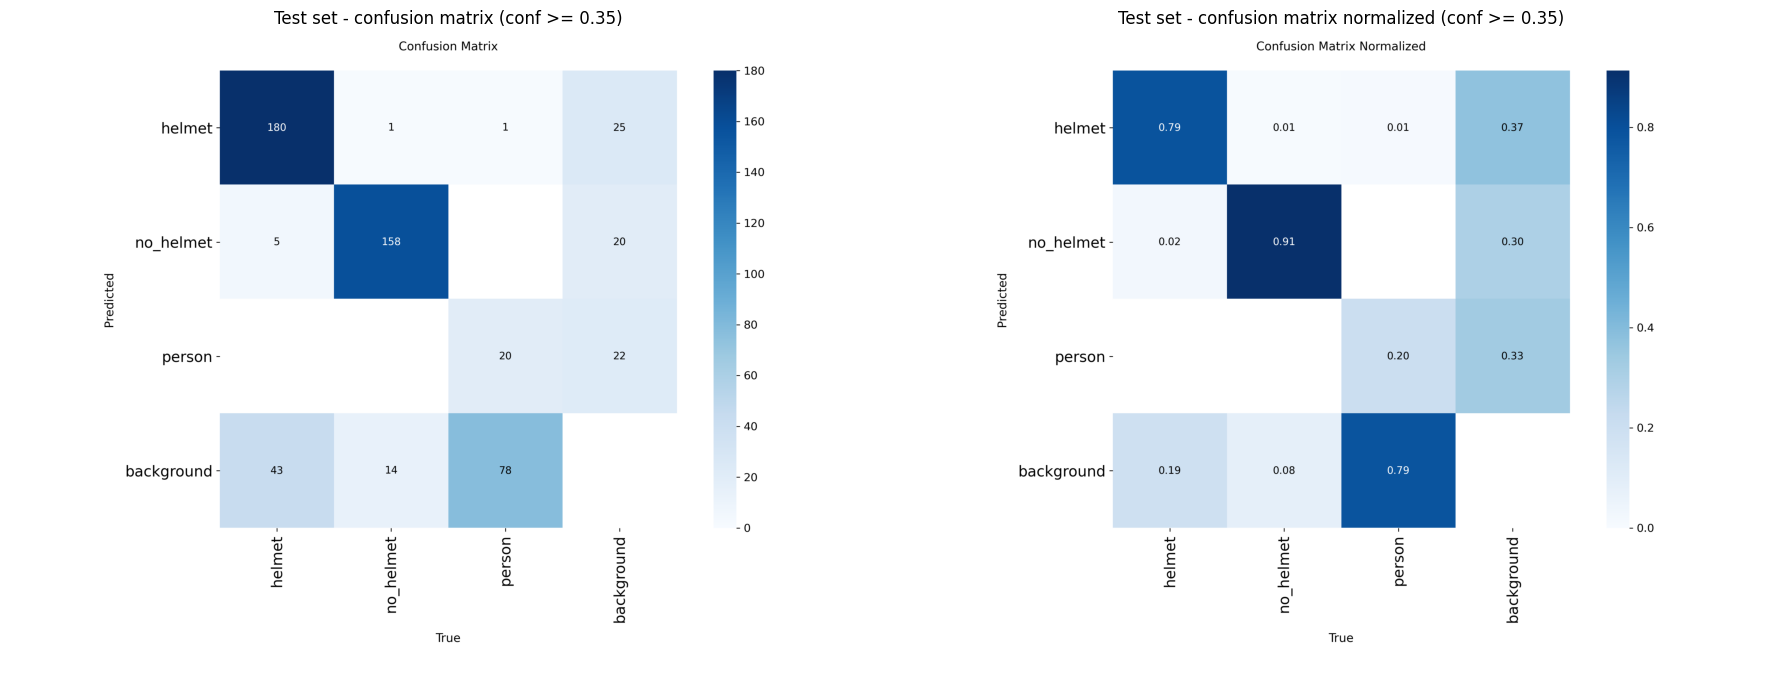

Largest confusions on the test set (count: TRUE -> PREDICTED):
    78      person -> background  missed (false negative)
    43      helmet -> background  missed (false negative)
    25  background -> helmet      false alarm (false positive)
    22  background -> person      false alarm (false positive)
    20  background -> no_helmet   false alarm (false positive)
    14   no_helmet -> background  missed (false negative)


In [ ]:
# ---- Confusion matrices (test set) at the deployment threshold ----
# Ultralytics builds its matrix at conf=0.001 (the mAP setting), which floods the "background" row with
# near-zero-confidence boxes. A second pass at CONF_INFER shows the errors the deployed system really makes.
cm_m = best_model.val(data=str(DATA_YAML), split="test", imgsz=IMGSZ, batch=16, device=DEVICE, plots=True,
                      conf=CONF_INFER, project=str(EVAL_OUT), name="test_confusion_conf", exist_ok=True, verbose=False)
for f in ["confusion_matrix.png", "confusion_matrix_normalized.png"]:
    shutil.copy(Path(cm_m.save_dir) / f, EVAL_OUT / f"test_{f}")
fig, axes = plt.subplots(1, 2, figsize=(18, 8))
for ax, f in zip(axes, ["confusion_matrix.png", "confusion_matrix_normalized.png"]):
    p = EVAL_OUT / f"test_{f}"
    if p.exists():
        ax.imshow(imread_rgb(p))
    ax.set_title(f"Test set - {f.replace('_', ' ')[:-4]} (conf >= {CONF_INFER})"); ax.axis("off")
plt.tight_layout(); plt.show()

# biggest confusions, read straight from the matrix (rows = predicted, columns = true)
cm = cm_m.confusion_matrix.matrix
labels = CLASSES + ["background"]
conf_pairs = [(int(cm[p, t]), labels[t], labels[p]) for p in range(len(labels)) for t in range(len(labels))
              if p != t and cm[p, t] > 0]
conf_pairs.sort(reverse=True)
print("Largest confusions on the test set (count: TRUE -> PREDICTED):")
for n, t, p in conf_pairs[:6]:
    kind = "missed (false negative)" if p == "background" else "false alarm (false positive)" if t == "background" else "wrong class"
    print(f"  {n:4d}  {t:>10} -> {p:<10}  {kind}")
save_summary("confusions", [dict(count=n, true=t, predicted=p) for n, t, p in conf_pairs[:6]])

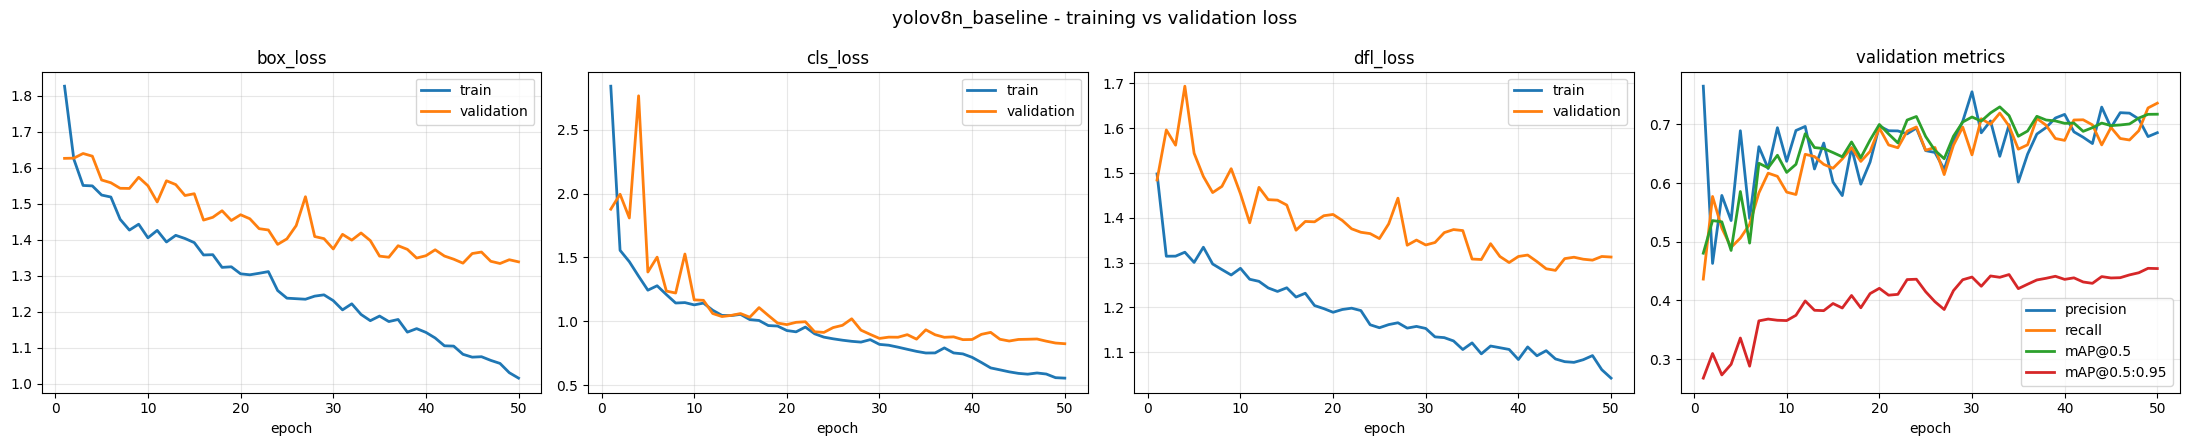

yolov8n_baseline: final val box loss 1.339 (min 1.334) -> validation loss still near its minimum: no strong overfitting.


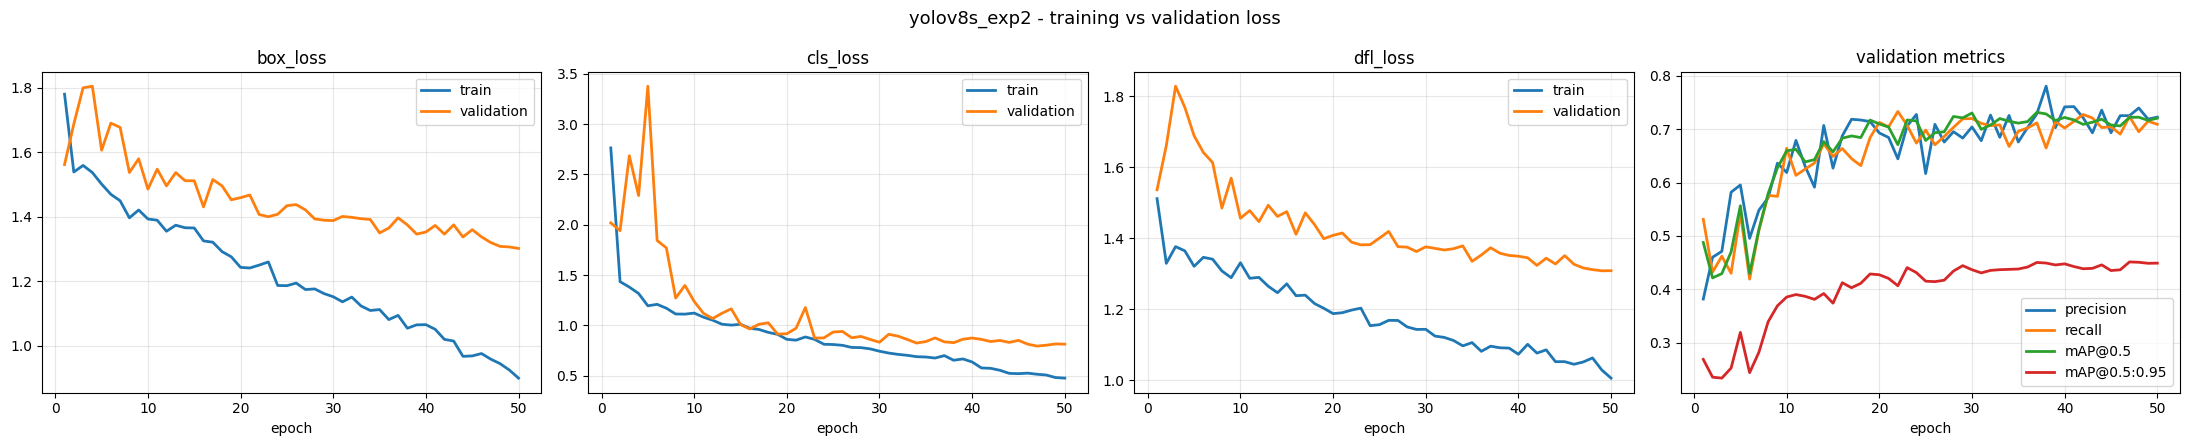

yolov8s_exp2: final val box loss 1.302 (min 1.302) -> validation loss still near its minimum: no strong overfitting.


PosixPath('/content/drive/MyDrive/cv_project/outputs/evaluation/loss_curves_best_model.png')

In [ ]:
# ---- Training & validation loss curves (+ metric curves) for every experiment ----
for info in experiment_results:
    res = pd.read_csv(Path(info["run_dir"]) / "results.csv"); res.columns = [c.strip() for c in res.columns]
    fig, axes = plt.subplots(1, 4, figsize=(22, 4.5))
    for ax, loss in zip(axes[:3], ["box_loss", "cls_loss", "dfl_loss"]):
        ax.plot(res["epoch"], res[f"train/{loss}"], label="train", lw=2)
        ax.plot(res["epoch"], res[f"val/{loss}"], label="validation", lw=2)
        ax.set_title(loss); ax.set_xlabel("epoch"); ax.legend(); ax.grid(alpha=.3)
    for k, lab in [("metrics/precision(B)", "precision"), ("metrics/recall(B)", "recall"),
                   ("metrics/mAP50(B)", "mAP@0.5"), ("metrics/mAP50-95(B)", "mAP@0.5:0.95")]:
        axes[3].plot(res["epoch"], res[k], label=lab, lw=2)
    axes[3].set_title("validation metrics"); axes[3].set_xlabel("epoch"); axes[3].legend(); axes[3].grid(alpha=.3)
    plt.suptitle(f"{info['name']} - training vs validation loss", fontsize=13); plt.tight_layout()
    plt.savefig(Path(info["run_dir"]) / "loss_curves.png", dpi=110); plt.show()
    gap = res["val/box_loss"].iloc[-1] - res["val/box_loss"].min()
    print(f"{info['name']}: final val box loss {res['val/box_loss'].iloc[-1]:.3f} (min {res['val/box_loss'].min():.3f}) -> "
          + ("validation loss still near its minimum: no strong overfitting." if gap < 0.05 else
             "validation loss rose after its minimum: mild overfitting, best.pt keeps the best epoch."))
shutil.copy(Path(exp_df.at[best_exp, "run_dir"]) / "loss_curves.png", EVAL_OUT / "loss_curves_best_model.png")

In [ ]:
# ---- Interpretation: best / worst class and why mistakes happen ----
tc = test_cls.set_index("cls")
best_c, worst_c = tc["mAP50_95"].idxmax(), tc["mAP50_95"].idxmin()
train_inst = split_df[split_df.split == "train"][CLASSES].sum()
size_by_cls = {}
for c in CLASSES:
    areas = [ (float(l.split()[3]) * float(l.split()[4])) for p in (DATASET / "labels" / "train").glob("*.txt")
              for l in p.read_text().splitlines() if l.strip() and int(l.split()[0]) == CLS2ID[c]]
    size_by_cls[c] = float(np.median(areas)) * 100 if areas else float("nan")

text = f'''
**Best class:** `{best_c}` — test mAP@0.5:0.95 = {tc.at[best_c, "mAP50_95"]:.3f}, mAP@0.5 = {tc.at[best_c, "mAP50"]:.3f}
({int(train_inst[best_c])} training instances; median box = {size_by_cls[best_c]:.2f}% of the image).

**Worst class:** `{worst_c}` — test mAP@0.5:0.95 = {tc.at[worst_c, "mAP50_95"]:.3f}, mAP@0.5 = {tc.at[worst_c, "mAP50"]:.3f}
({int(train_inst[worst_c])} training instances; median box = {size_by_cls[worst_c]:.2f}% of the image).

**Training instances per class:** {", ".join(f"{c}: {int(train_inst[c])}" for c in CLASSES)}

**Why the model makes mistakes (evidence from this run):**
- **Class imbalance** — `{train_inst.idxmax()}` has {int(train_inst.max())} training boxes vs {int(train_inst.min())} for `{train_inst.idxmin()}`, so the model sees far fewer examples of the rarer class.
- **Small objects** — heads and helmets in crowd / far-away shots cover a tiny fraction of the image (median helmet box ≈ {size_by_cls["helmet"]:.2f}% of the image), leaving few pixels to tell a helmet from hair or a cap.
- **Look-alikes** — caps, hoods, hair and headscarves resemble helmets at low resolution, causing `no_helmet ↔ helmet` swaps.
- **Inconsistent `person` labels in the public source data** — many people in the original dataset were never labelled as `person`, so a correct `person` detection is sometimes scored as a false positive. The manual annotation batch fixes this for the hand-labelled images.
- **Lighting / blur** — dark and motion-blurred images reduce contrast at object edges (see error analysis, Phase 10).
'''
display(Markdown(text))
save_summary("interpretation", dict(best_class=best_c, worst_class=worst_c, train_instances=train_inst.to_dict(),
                                    median_box_pct=size_by_cls, text=text))


**Best class:** `no_helmet` — test mAP@0.5:0.95 = 0.577, mAP@0.5 = 0.922
(1034 training instances; median box = 0.39% of the image).

**Worst class:** `person` — test mAP@0.5:0.95 = 0.122, mAP@0.5 = 0.259
(525 training instances; median box = 4.04% of the image).

**Training instances per class:** helmet: 1183, no_helmet: 1034, person: 525

**Why the model makes mistakes (evidence from this run):**
- **Class imbalance** — `helmet` has 1183 training boxes vs 525 for `person`, so the model sees far fewer examples of the rarer class.
- **Small objects** — heads and helmets in crowd / far-away shots cover a tiny fraction of the image (median helmet box ≈ 0.51% of the image), leaving few pixels to tell a helmet from hair or a cap.
- **Look-alikes** — caps, hoods, hair and headscarves resemble helmets at low resolution, causing `no_helmet ↔ helmet` swaps.
- **Inconsistent `person` labels in the public source data** — many people in the original dataset were never labelled as `person`, so a correct `person` detection is sometimes scored as a false positive. The manual annotation batch fixes this for the hand-labelled images.
- **Lighting / blur** — dark and motion-blurred images reduce contrast at object edges (see error analysis, Phase 10).


---
## 🔍 Phase 9 — Inference on New (Unseen) Data

The test images were never used for training or model selection, so they are genuinely unseen. The saved prediction images show **bounding boxes, predicted labels and confidence scores**. Each image also gets a **compliance status** — the actual output a safety officer would use.

In [ ]:
model = YOLO(str(BEST_PT))
results = model.predict(
    source=str(DATASET / "images" / "test"),
    conf=CONF_INFER,
    save=True,
    project=str(PRED_OUT),
    name="test_predictions",
    exist_ok=True,
    device=DEVICE,
    verbose=False,
)
pred_dir = Path(results[0].save_dir)
pred_imgs = sorted([p for p in pred_dir.glob("*") if p.suffix.lower() in IMG_EXT])
print(f"Saved {len(pred_imgs)} prediction images to {pred_dir}")
if len(pred_imgs) < 15:
    print("⚠️  Fewer than 15 test images - add photos to unseen_images/ (next cell) to reach the brief's minimum of 15.")

def compliance(r):
    names = [r.names[int(c)] for c in r.boxes.cls.tolist()]
    cnt = Counter(names)
    status = "VIOLATION" if cnt.get("no_helmet", 0) else ("COMPLIANT" if cnt.get("helmet", 0) else "NO HEADS DETECTED")
    return cnt, status

rows = []
for r in results:
    cnt, status = compliance(r)
    rows.append(dict(image=Path(r.path).name, helmet=cnt.get("helmet", 0), no_helmet=cnt.get("no_helmet", 0),
                     person=cnt.get("person", 0), status=status,
                     mean_conf=round(float(r.boxes.conf.mean()), 3) if len(r.boxes) else None))
compliance_df = pd.DataFrame(rows)
compliance_df.to_csv(PRED_OUT / "test_compliance_report.csv", index=False)
display(compliance_df.head(15))
print(compliance_df["status"].value_counts().to_string())

# ---- 4x4 grid of prediction images ----
pick = [p for p in pred_imgs if p.stem in set(compliance_df.sort_values("no_helmet", ascending=False).image.str.rsplit(".", n=1).str[0].head(8))]
pick += [p for p in pred_imgs if p not in pick][: 16 - len(pick)]
fig, axes = plt.subplots(4, 4, figsize=(20, 20))
status_of = dict(zip(compliance_df.image.str.rsplit(".", n=1).str[0], compliance_df.status))
for ax, p in zip(axes.flat, pick):
    ax.imshow(imread_rgb(p)); st = status_of.get(p.stem, "")
    ax.set_title(f"{p.name}\n{st}", fontsize=9, color="red" if st == "VIOLATION" else "green"); ax.axis("off")
for ax in axes.flat[len(pick):]:
    ax.axis("off")
plt.suptitle(f"Predictions on unseen test images (conf >= {CONF_INFER})", fontsize=15); plt.tight_layout()
plt.savefig(PRED_OUT / "prediction_grid.png", dpi=100); plt.show()
save_summary("inference", dict(n_prediction_images=len(pred_imgs), conf=CONF_INFER,
                               status_counts=compliance_df["status"].value_counts().to_dict(), pred_dir=str(pred_dir)))

Output hidden; open in https://colab.research.google.com to view.

Results saved to /content/drive/MyDrive/cv_project/outputs/predictions/unseen_images


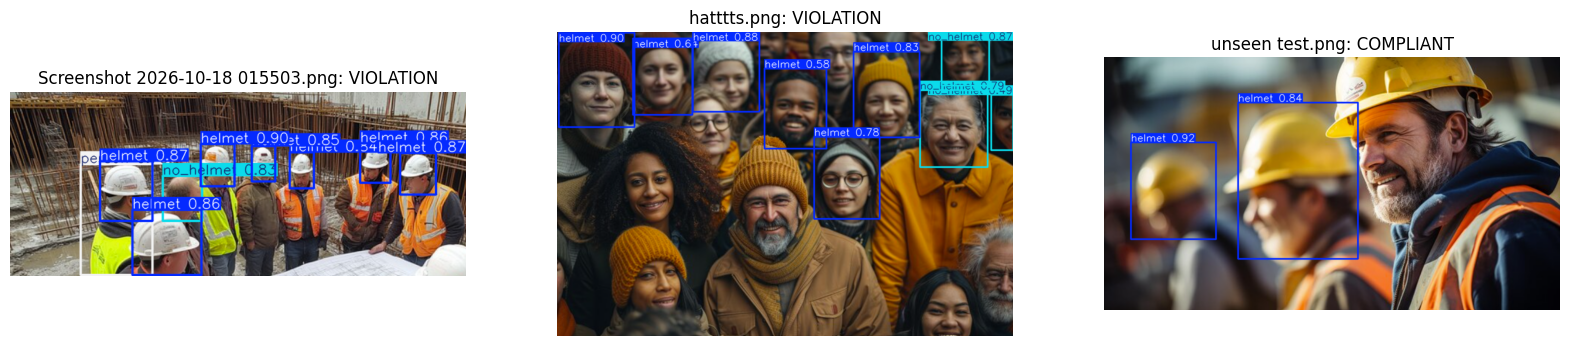

In [ ]:
# ---- Optional: your own new photos (put .jpg/.png files in MyDrive/cv_project/unseen_images/) ----
IMG_EXT = (".png", ".jpg", ".jpeg", ".bmp")
own = [p for p in UNSEEN_DIR.glob("*") if p.suffix.lower() in IMG_EXT]
if own:
    r_own = model.predict(source=str(UNSEEN_DIR), conf=CONF_INFER, save=True, project=str(PRED_OUT),
                          name="unseen_images", exist_ok=True, device=DEVICE, verbose=False)
    fig, axes = plt.subplots(1, min(4, len(r_own)), figsize=(20, 5), squeeze=False)
    for ax, r in zip(axes.flat, r_own):
        ax.imshow(r.plot()[:, :, ::-1]); ax.set_title(f"{Path(r.path).name}: {compliance(r)[1]}"); ax.axis("off")
    plt.show()
else:
    print("No extra images in", UNSEEN_DIR, "- skipping (optional).")

In [ ]:
# ---- Video inference (recommended) ----
# Put any short worksite clip in MyDrive/cv_project/videos/ (e.g. a free construction clip from pexels.com).
# If none is provided, a short demo video is assembled from unseen test images so the pipeline is still shown.
videos = sorted([p for p in VIDEO_DIR.glob("*") if p.suffix.lower() in (".mp4", ".avi", ".mov", ".mkv")])
if videos:
    video_in = videos[0]
else:
    video_in = VIDEO_DIR / "demo_input_from_test_images.mp4"
    frames = sorted((DATASET / "images" / "test").glob("*.jpg"))[:30]
    vw = cv2.VideoWriter(str(video_in), cv2.VideoWriter_fourcc(*"mp4v"), 10, (640, 640))
    for f in frames:
        fr = cv2.resize(cv2.imread(str(f)), (640, 640))
        for _ in range(10):          # hold each image for 1 second
            vw.write(fr)
    vw.release()
    print("No video provided - built a demo video from test images:", video_in)

cap = cv2.VideoCapture(str(video_in))
fps = cap.get(cv2.CAP_PROP_FPS) or 25
W, H = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
video_out = DEMO_OUT / f"{video_in.stem}_detections.mp4"
writer = cv2.VideoWriter(str(video_out), cv2.VideoWriter_fourcc(*"mp4v"), fps, (W, H))
n_frames, n_violation_frames, t0 = 0, 0, time.time()
while True:
    ok, frame = cap.read()
    if not ok:
        break
    r = model.predict(frame, conf=CONF_INFER, device=DEVICE, verbose=False)[0]
    cnt, status = compliance(r)
    out = r.plot()
    col = (0, 0, 255) if status == "VIOLATION" else (0, 170, 0)
    cv2.rectangle(out, (0, 0), (W, 34), (0, 0, 0), -1)
    cv2.putText(out, f"{status} | helmet:{cnt.get('helmet', 0)} no_helmet:{cnt.get('no_helmet', 0)} person:{cnt.get('person', 0)}",
                (8, 24), cv2.FONT_HERSHEY_SIMPLEX, 0.65, col, 2, cv2.LINE_AA)
    writer.write(out)
    n_frames += 1; n_violation_frames += status == "VIOLATION"
    if n_frames == 15:
        cv2.imwrite(str(DEMO_OUT / "video_frame_example.jpg"), out)
cap.release(); writer.release()
fps_proc = n_frames / max(time.time() - t0, 1e-6)
print(f"Processed {n_frames} frames at {fps_proc:.1f} FPS -> {video_out}")
print(f"Frames with a violation: {n_violation_frames} ({100 * n_violation_frames / max(n_frames, 1):.0f}%)")
save_summary("video", dict(input=str(video_in), output=str(video_out), frames=n_frames, fps=round(fps_proc, 1),
                           violation_frames=int(n_violation_frames), user_video=bool(videos)))

Processed 300 frames at 55.8 FPS -> /content/drive/MyDrive/cv_project/outputs/demo_results/demo_input_from_test_images_detections.mp4
Frames with a violation: 210 (70%)


---
## 🧪 Phase 10 — Error Analysis

Every test prediction is matched to the ground truth (greedy matching by IoU, highest confidence first) and classified:

| Error type | Rule |
|---|---|
| **False positive** | Prediction overlaps no true object (IoU < 0.3) — a false alarm |
| **False negative** | True object with no prediction — a miss |
| **Wrong class** | Box in the right place (IoU ≥ 0.5) but wrong label, e.g. `no_helmet` predicted as `helmet` |
| **Poor bounding box** | Right class but loose / shifted box (0.3 ≤ IoU < 0.5) |

Each error is tagged with measurable causes — **small object**, **poor lighting**, **blur**, **occlusion / crowd**, **object cut by the image edge**, or **likely annotation mistake** (a confident detection with no matching label). The notebook then picks the most informative cases for **manual review**.

In [ ]:
def analyse_image(img_path, result):
    img = cv2.imread(str(img_path)); h, w = img.shape[:2]
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    brightness, blur = float(gray.mean()), float(cv2.Laplacian(gray, cv2.CV_64F).var())
    gts = read_yolo_label(DATASET / "labels" / "test" / f"{Path(img_path).stem}.txt", w, h)
    preds = [(int(c), *b, float(s)) for c, b, s in zip(result.boxes.cls.tolist(), result.boxes.xyxy.tolist(), result.boxes.conf.tolist())]
    preds.sort(key=lambda p: -p[5])
    gt_boxes = np.array([g[1:5] for g in gts]).reshape(-1, 4)
    gt_overlap = iou_matrix(gt_boxes, gt_boxes); np.fill_diagonal(gt_overlap, 0)
    ious = iou_matrix([p[1:5] for p in preds], gt_boxes)
    used, errors, tp = set(), [], 0

    def causes(box, cls_name, kind, conf=None, gt_idx=None):
        x1, y1, x2, y2 = box; rel = (x2 - x1) * (y2 - y1) / (w * h); c = []
        if rel < 0.003: c.append("Small object")
        if brightness < 70: c.append("Poor lighting")
        if blur < 100: c.append("Blurry image")
        if gt_idx is not None and gt_overlap[gt_idx].max(initial=0) > 0.15: c.append("Occlusion / crowded scene")
        if min(x1, y1) < 3 or x2 > w - 3 or y2 > h - 3: c.append("Partially visible at image edge")
        if kind == "False positive" and conf is not None and conf >= 0.6: c.append("Likely missing label (annotation mistake)")
        if kind == "False positive" and cls_name == "person": c.append("Inconsistent person labels in source data")
        if kind == "Wrong class": c.append("Similar appearance (cap/hair/hood vs helmet)" if "helmet" in cls_name else "Class confusion")
        if kind == "Poor bounding box": c.append("Box boundary ambiguity / loose annotation")
        return c or ["Unusual pose or appearance"], rel

    for pi, p in enumerate(preds):
        cand = [(ious[pi, gi], gi) for gi in range(len(gts)) if gi not in used]
        best_iou, gi = max(cand, default=(0.0, None))
        pname = CLASSES[p[0]]
        if gi is not None and best_iou >= IOU_POOR_BOX:
            used.add(gi); gname = CLASSES[gts[gi][0]]
            if best_iou >= IOU_MATCH and gname == pname:
                tp += 1; continue
            kind = "Wrong class" if gname != pname else "Poor bounding box"
            cs, rel = causes(gts[gi][1:5], gname + pname, kind, p[5], gi)
            errors.append(dict(image=Path(img_path).name, actual=gname, predicted=f"{pname} ({p[5]:.2f})", error_type=kind,
                               iou=round(best_iou, 2), conf=p[5], rel_area=rel, causes="; ".join(cs), box=p[1:5], gt_box=gts[gi][1:5]))
        else:
            cs, rel = causes(p[1:5], pname, "False positive", p[5])
            errors.append(dict(image=Path(img_path).name, actual="nothing (background)", predicted=f"{pname} ({p[5]:.2f})",
                               error_type="False positive", iou=round(best_iou, 2), conf=p[5], rel_area=rel, causes="; ".join(cs),
                               box=p[1:5], gt_box=None))
    for gi, g in enumerate(gts):
        if gi not in used:
            cs, rel = causes(g[1:5], CLASSES[g[0]], "False negative", gt_idx=gi)
            errors.append(dict(image=Path(img_path).name, actual=CLASSES[g[0]], predicted="not detected", error_type="False negative",
                               iou=0.0, conf=0.0, rel_area=rel, causes="; ".join(cs), box=None, gt_box=g[1:5]))
    return errors, tp, len(gts), len(preds)

all_errors, totals = [], Counter()
for r in results:
    e, tp, n_gt, n_pred = analyse_image(r.path, r)
    all_errors += e; totals.update(tp=tp, gt=n_gt, pred=n_pred)
err_df = pd.DataFrame(all_errors)
err_df.drop(columns=["box", "gt_box"]).to_csv(ERR_OUT / "all_errors_test.csv", index=False)

print(f"Test set at conf={CONF_INFER}: {totals['gt']} true objects, {totals['pred']} predictions, {totals['tp']} correct")
type_counts = err_df["error_type"].value_counts()
display(type_counts.to_frame("count"))
cause_counts = Counter(c for cs in err_df["causes"] for c in cs.split("; "))
display(pd.Series(cause_counts).sort_values(ascending=False).to_frame("errors with this cause"))
display(pd.crosstab(err_df["actual"], err_df["error_type"]))
save_summary("error_counts", dict(types=type_counts.to_dict(), causes=dict(cause_counts), totals=dict(totals)))

Test set at conf=0.35: 500 true objects, 438 predictions, 347 correct


,count
error_type,
False negative,140
False positive,78
Poor bounding box,7
Wrong class,6


,errors with this cause
Small object,98
Partially visible at image edge,83
Occlusion / crowded scene,48
Unusual pose or appearance,27
Likely missing label (annotation mistake),24
Inconsistent person labels in source data,24
Poor lighting,13
Box boundary ambiguity / loose annotation,7
Similar appearance (cap/hair/hood vs helmet),6


error_type,False negative,False positive,Poor bounding box,Wrong class
actual,,,,
helmet,45,0,2,4
no_helmet,15,0,4,1
nothing (background),0,78,0,0
person,80,0,1,1


In [ ]:
# ---- Pick the most informative error cases for manual review (diverse types, highest impact) ----
quota = {"False negative": 4, "False positive": 3, "Wrong class": 3, "Poor bounding box": 2}
picked = []
for kind, n in quota.items():
    sub = err_df[(err_df.error_type == kind) & ~err_df.image.isin(err_df.loc[picked, "image"])]
    sub = sub.sort_values("rel_area", ascending=False) if kind == "False negative" else sub.sort_values("conf", ascending=False)
    sub = sub.drop_duplicates("image")        # one case per image => more variety
    # rotate across classes so the cases are not all of one class
    key = "actual" if kind != "False positive" else "predicted"
    queues = {c: g.index.tolist() for c, g in sub.groupby(sub[key].str.split(" ").str[0], sort=False)}
    chosen = []
    while len(chosen) < n and any(queues.values()):
        for c in list(queues):
            if queues[c] and len(chosen) < n:
                chosen.append(queues[c].pop(0))
    picked += chosen
rest = err_df.drop(index=picked)
rest = rest.assign(seen=rest.image.isin(err_df.loc[picked, "image"])).sort_values(["seen", "conf"], ascending=[True, False])
rest = rest.drop_duplicates("image")
picked += rest.index[: max(0, N_ERROR_CASES - len(picked))].tolist()
cases = err_df.loc[picked].reset_index(drop=True)
cases.index = cases.index + 1

def crop_view(row):
    img = imread_rgb(DATASET / "images" / "test" / row["image"]); h, w = img.shape[:2]
    gts = read_yolo_label(DATASET / "labels" / "test" / f"{Path(row['image']).stem}.txt", w, h)
    vis = draw_boxes(img, gts, thickness=1)                                    # all ground truth (thin)
    focus = row["box"] if row["box"] is not None else row["gt_box"]
    if row["gt_box"] is not None:
        x1, y1, x2, y2 = map(int, row["gt_box"]); cv2.rectangle(vis, (x1, y1), (x2, y2), (255, 255, 255), 2)
    if row["box"] is not None:
        x1, y1, x2, y2 = map(int, row["box"]); cv2.rectangle(vis, (x1, y1), (x2, y2), (255, 0, 255), 2)
    x1, y1, x2, y2 = focus; cx, cy = (x1 + x2) / 2, (y1 + y2) / 2
    half = max(60, 2.0 * max(x2 - x1, y2 - y1))
    a, b = int(max(0, cx - half)), int(max(0, cy - half))
    return vis, vis[b:int(min(h, cy + half)), a:int(min(w, cx + half))]

n = len(cases); fig, axes = plt.subplots(n, 2, figsize=(12, 4.2 * n), gridspec_kw={"width_ratios": [2, 1]})
axes = np.atleast_2d(axes)
for k, (i, row) in enumerate(cases.iterrows()):
    full, crop = crop_view(row)
    axes[k, 0].imshow(full); axes[k, 1].imshow(crop)
    axes[k, 0].set_title(f"#{i} {row['image']} | {row['error_type']}: actual={row['actual']}, predicted={row['predicted']}", fontsize=9)
    axes[k, 1].set_title(row["causes"][:70], fontsize=8)
    for ax in axes[k]: ax.axis("off")
    cv2.imwrite(str(ERR_OUT / f"case_{i:02d}_{row['error_type'].replace(' ', '_')}.jpg"), cv2.cvtColor(full, cv2.COLOR_RGB2BGR))
plt.suptitle("Error cases (white = true box, magenta = prediction, thin coloured = all labels)", fontsize=12, y=1.0)
plt.tight_layout(); plt.savefig(ERR_OUT / "error_cases.png", dpi=80); plt.show()

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
# ---- Manual review: look at each case above and write YOUR reason in your own words ----
# Leave a note empty to keep the automatically measured cause.
MANUAL_REVIEW_NOTES = {
    1: "",
    2: "",
    3: "",
    4: "",
    5: "",
    6: "",
    7: "",
    8: "",
    9: "",
    10: "",
    11: "",
    12: "",
}

error_table = pd.DataFrame({
    "Image": cases["image"],
    "Actual Object": cases["actual"],
    "Model Prediction": cases["predicted"],
    "Error Type": cases["error_type"],
    "Possible Reason": [MANUAL_REVIEW_NOTES.get(i) or c for i, c in zip(cases.index, cases["causes"])],
})
display(error_table)
error_table.to_csv(ERR_OUT / "error_analysis_table.csv", index_label="#")
(ERR_OUT / "error_analysis_table.md").write_text(error_table.to_markdown())

# ---- Data-driven improvement suggestions (brief: at least three) ----
improvements = []
tc = test_cls.set_index("cls")
weak = tc["mAP50_95"].idxmin()
improvements.append(f"Add more training images for the weakest class `{weak}` (test mAP@0.5:0.95 = {tc.at[weak, 'mAP50_95']:.2f}) and rebalance classes with targeted collection.")
if cause_counts.get("Small object", 0):
    improvements.append(f"Small objects caused {cause_counts['Small object']} errors: train at a higher resolution (imgsz=960) or use tiled/SAHI inference for far-away workers.")
if cause_counts.get("Likely missing label (annotation mistake)", 0) or cause_counts.get("Inconsistent person labels in source data", 0):
    improvements.append("Re-annotate the public images with missing labels (especially `person`) using the same guidelines as my manual batch - the audit showed the source labels are incomplete.")
if cause_counts.get("Poor lighting", 0) or cause_counts.get("Blurry image", 0):
    improvements.append("Collect more low-light and motion-blurred site images and enable stronger brightness/blur augmentation.")
if type_counts.get("Wrong class", 0):
    improvements.append("Add hard-negative examples of caps, hoods and headscarves labelled `no_helmet` to reduce helmet / no_helmet confusion.")
improvements.append("Train a larger model (YOLOv8m) for more epochs with cosine LR, and tune the confidence threshold per class to favour no_helmet recall.")
improvements.append("Test on real CCTV footage from local sites and add tracking (ByteTrack) so one violation is counted once per person, not once per frame.")
display(Markdown("**Suggested improvements:**\n" + "\n".join(f"{i}. {s}" for i, s in enumerate(improvements, 1))))
save_summary("error_analysis", dict(table=error_table.reset_index().rename(columns={"index": "#"}).to_dict("records"),
                                    improvements=improvements))

,Image,Actual Object,Model Prediction,Error Type,Possible Reason
1,hard_hat_workers1029.jpg,person,not detected,False negative,Occlusion / crowded scene
2,hard_hat_workers4352.jpg,helmet,not detected,False negative,Poor lighting; Partially visible at image edge
3,hard_hat_workers1604.jpg,no_helmet,not detected,False negative,Partially visible at image edge
4,hard_hat_workers3408.jpg,person,not detected,False negative,Partially visible at image edge
5,hard_hat_workers3110.jpg,nothing (background),helmet (0.83),False positive,Poor lighting; Partially visible at image edge; Likely missing label (annota...
6,hard_hat_workers2080.jpg,nothing (background),person (0.78),False positive,Likely missing label (annotation mistake); Inconsistent person labels in sou...
7,hard_hat_workers306.jpg,nothing (background),no_helmet (0.73),False positive,Small object; Likely missing label (annotation mistake)
8,hard_hat_workers43.jpg,helmet,no_helmet (0.82),Wrong class,Similar appearance (cap/hair/hood vs helmet)
9,hard_hat_workers3593.jpg,person,helmet (0.49),Wrong class,Occlusion / crowded scene; Partially visible at image edge; Similar appearan...
10,hard_hat_workers447.jpg,no_helmet,helmet (0.38),Wrong class,Similar appearance (cap/hair/hood vs helmet)


**Suggested improvements:**
1. Add more training images for the weakest class `person` (test mAP@0.5:0.95 = 0.12) and rebalance classes with targeted collection.
2. Small objects caused 98 errors: train at a higher resolution (imgsz=960) or use tiled/SAHI inference for far-away workers.
3. Re-annotate the public images with missing labels (especially `person`) using the same guidelines as my manual batch - the audit showed the source labels are incomplete.
4. Collect more low-light and motion-blurred site images and enable stronger brightness/blur augmentation.
5. Add hard-negative examples of caps, hoods and headscarves labelled `no_helmet` to reduce helmet / no_helmet confusion.
6. Train a larger model (YOLOv8m) for more epochs with cosine LR, and tune the confidence threshold per class to favour no_helmet recall.
7. Test on real CCTV footage from local sites and add tracking (ByteTrack) so one violation is counted once per person, not once per frame.

---
## 📝 Final Deliverables — README results, Report PDF, LinkedIn post, checklist
These cells read everything from `outputs/run_summary.json`, so they can be re-run at any time (even in a new session).

> ✍️ The brief asks for the LinkedIn report **in your own words**. The generated text is a factual draft filled with *your* numbers — read it, then rewrite the overview and "What I learned" sections in your own voice before posting.

In [ ]:
S = load_summary()
ev = pd.DataFrame(S["evaluation"]["overall"]).set_index("split")
pc = pd.DataFrame(S["evaluation"]["per_class"])
tr = pd.DataFrame(S["training"]["experiments"]).set_index("name")
best_name = S["training"]["best_experiment"]; bt = tr.loc[best_name]
spl = pd.DataFrame(S["split"]).set_index("split")
dc = S["data_collection"]; an = S["annotation"]; it = S["interpretation"]
t = ev.loc["test"]
n_total = int(spl["images"].sum())
annot_line = (f"{an['manual_images']} images annotated by hand in Roboflow" if an["manual_done"]
              else f"manual Roboflow batch of {an['manual_batch_prepared']} images prepared (import pending)")

results_md = f'''| Metric (test set) | Value |
|---|---|
| Precision | {t.precision:.3f} |
| Recall | {t.recall:.3f} |
| mAP@0.5 | {t.mAP50:.3f} |
| mAP@0.5:0.95 | {t.mAP50_95:.3f} |

| Class | Precision | Recall | mAP@0.5 | mAP@0.5:0.95 |
|---|---|---|---|---|
''' + "\n".join(f"| {r.cls} | {r.precision:.3f} | {r.recall:.3f} | {r.mAP50:.3f} | {r.mAP50_95:.3f} |"
                for r in pc[pc.split == "test"].itertuples()) + f'''

| Experiment | Model | Epochs | Train time | GPU | Val mAP@0.5 | Val mAP@0.5:0.95 |
|---|---|---|---|---|---|---|
''' + "\n".join(f"| {n} | {r.weights} | {r.epochs} | {r.train_minutes} min | {r.gpu} | {r.val_mAP50:.3f} | {r.val_mAP50_95:.3f} |"
                for n, r in tr.iterrows()) + f'''

**Dataset:** {n_total} images ({", ".join(f"{s}: {int(spl.at[s, 'images'])}" for s in ["train", "val", "test"])}), {annot_line}, {dc["duplicates_removed"]} near-duplicates removed.
**Best model:** `{best_name}` -> `models/best.pt`'''

readme = ROOT / "README.md"
if readme.exists():
    txt = readme.read_text()
    txt = re.sub(r"<!-- RESULTS:START -->.*<!-- RESULTS:END -->",
                 "<!-- RESULTS:START -->\n" + results_md + "\n<!-- RESULTS:END -->", txt, flags=re.S)
    readme.write_text(txt); print("README.md results section updated")
display(Markdown(results_md))

README.md results section updated


| Metric (test set) | Value |
|---|---|
| Precision | 0.727 |
| Recall | 0.655 |
| mAP@0.5 | 0.679 |
| mAP@0.5:0.95 | 0.401 |

| Class | Precision | Recall | mAP@0.5 | mAP@0.5:0.95 |
|---|---|---|---|---|
| helmet | 0.850 | 0.793 | 0.856 | 0.504 |
| no_helmet | 0.828 | 0.919 | 0.921 | 0.577 |
| person | 0.503 | 0.253 | 0.259 | 0.122 |

| Experiment | Model | Epochs | Train time | GPU | Val mAP@0.5 | Val mAP@0.5:0.95 |
|---|---|---|---|---|---|---|
| yolov8n_baseline | yolov8n.pt | 50 | 6.9 min | Tesla T4 | 0.717 | 0.455 |
| yolov8s_exp2 | yolov8s.pt | 50 | 6.5 min | Tesla T4 | 0.722 | 0.451 |

**Dataset:** 500 images (train: 349, val: 100, test: 51), manual Roboflow batch of 120 images prepared (import pending), 92 near-duplicates removed.
**Best model:** `yolov8n_baseline` -> `models/best.pt`

In [ ]:
# ---- LinkedIn-ready portfolio report (template sections 1-10 of the brief) ----
cls_txt = ", ".join(f"`{c}`" for c in CLASSES)
err = S["error_counts"]["types"]; causes = S["error_counts"]["causes"]
top_causes = ", ".join(k.lower() for k, _ in sorted(causes.items(), key=lambda kv: -kv[1])[:3])
linkedin = f'''# {PROJECT_TITLE}

## 1. Project Overview
I built a computer-vision safety system that detects whether workers are wearing safety helmets. Helmet rules are hard to enforce by watching cameras manually, so an automatic detector can flag violations as they happen. The model detects three classes - helmet, no_helmet (a bare head) and person - and for every image or video frame it draws labelled bounding boxes with confidence scores and marks the scene as COMPLIANT or VIOLATION. The goal was to go through the complete AI workflow, from data collection and annotation to training, evaluation, error analysis and a demo.

## 2. Tools and Technologies Used
Python, Google Colab (GPU: {bt.gpu}), Google Drive, YOLOv8, Ultralytics, OpenCV, Roboflow Annotate, Pandas, Matplotlib, ImageHash, Gradio and Streamlit.

## 3. Dataset Preparation
I started from the public Hard Hat Workers dataset (Kaggle, CC0 license, {dc["raw_images"]} images), removed {dc["duplicates_removed"]} near-duplicate images with perceptual hashing, and curated {n_total} images so that every class and difficult condition (small, dark, blurry and crowded scenes) is represented. {annot_line[0].upper() + annot_line[1:]}, following strict annotation guidelines, and audited my labels against the original ones. I converted all annotations from Pascal VOC to YOLO format and created a stratified 70/20/10 split ({int(spl.at["train", "images"])} train / {int(spl.at["val", "images"])} validation / {int(spl.at["test", "images"])} test).

## 4. Model Training
I trained a YOLOv8n baseline and a YOLOv8s experiment on Google Colab using pretrained COCO weights, image size {IMGSZ} and {int(bt.epochs)} epochs (batch {int(bt.batch)}). The best model ({bt.weights}) took {bt.train_minutes} minutes on a {bt.gpu} and was selected using validation mAP; its best checkpoint is saved as best.pt.

## 5. Evaluation Results
On the unseen test set the model reached precision {t.precision:.2f}, recall {t.recall:.2f}, mAP@0.5 {t.mAP50:.2f} and mAP@0.5:0.95 {t.mAP50_95:.2f}. The best-performing class was {it["best_class"]} and the weakest was {it["worst_class"]}. I also studied the confusion matrix and training/validation loss curves to understand behaviour across classes.

## 6. Inference Results
I tested the model on {S["inference"]["n_prediction_images"]} unseen images: it draws bounding boxes, labels and confidence scores and reports a compliance status for each image. I also ran it on video ({S["video"]["frames"]} frames at about {S["video"]["fps"]} FPS) and built a web demo where anyone can upload a photo.

## 7. Error Analysis
I matched every prediction with the ground truth and found {err.get("False negative", 0)} false negatives, {err.get("False positive", 0)} false positives, {err.get("Wrong class", 0)} wrong-class predictions and {err.get("Poor bounding box", 0)} poor boxes. The most common causes were {top_causes}. Some "false positives" were actually correct detections of people the original dataset never labelled - a reminder that label quality limits measured accuracy.

## 8. What I Learned
- How to choose, legally source and clean a computer-vision dataset (including duplicate removal)
- Manual bounding-box annotation and writing clear annotation guidelines
- Converting Pascal VOC annotations to the YOLO label format
- Training and comparing YOLOv8 models with transfer learning on Google Colab
- What precision, recall, mAP@0.5 and mAP@0.5:0.95 really measure
- That data quality and consistent labels matter as much as the model
- How systematic error analysis turns mistakes into a concrete improvement plan

## 9. Future Improvements
''' + "\n".join(f"- {s}" for s in S["error_analysis"]["improvements"][:5]) + f'''

## 10. LinkedIn Post
Today, I completed an end-to-end Computer Vision project as part of the AIRI Team PITB AI Internship Task 1.

I built a Safety Helmet Detection System using YOLOv8 that flags workers without helmets in images and video.

The project covered the complete AI workflow:
- Problem selection
- Data collection ({n_total} curated images, duplicates removed)
- Image annotation in Roboflow
- YOLO-format dataset preparation
- Model training on Google Colab (YOLOv8n vs YOLOv8s)
- Model evaluation (mAP@0.5 = {t.mAP50:.2f} on unseen test images)
- Inference on unseen images and video
- Error analysis
- Final documentation

This project helped me understand how real-world Computer Vision systems are developed beyond just training a model. I learned the importance of dataset quality, annotation consistency, evaluation metrics, and error analysis.

Tools used: Python, Google Colab, YOLOv8, Ultralytics, OpenCV, and Roboflow.

Key learning: A good AI model depends not only on the algorithm, but also on clean data, correct labels, proper evaluation, and continuous improvement.

#ComputerVision #DeepLearning #YOLOv8 #ArtificialIntelligence #MachineLearning #Python #AIRI #PITB #AIInternship
'''
(REPORT / "linkedin_portfolio_report.md").write_text(linkedin)
print("Saved", REPORT / "linkedin_portfolio_report.md")
display(Markdown(linkedin))

Saved /content/drive/MyDrive/cv_project/report/linkedin_portfolio_report.md


# Safety Helmet Detection Using YOLOv8

## 1. Project Overview
I built a computer-vision safety system that detects whether workers are wearing safety helmets. Helmet rules are hard to enforce by watching cameras manually, so an automatic detector can flag violations as they happen. The model detects three classes - helmet, no_helmet (a bare head) and person - and for every image or video frame it draws labelled bounding boxes with confidence scores and marks the scene as COMPLIANT or VIOLATION. The goal was to go through the complete AI workflow, from data collection and annotation to training, evaluation, error analysis and a demo.

## 2. Tools and Technologies Used
Python, Google Colab (GPU: Tesla T4), Google Drive, YOLOv8, Ultralytics, OpenCV, Roboflow Annotate, Pandas, Matplotlib, ImageHash, Gradio and Streamlit.

## 3. Dataset Preparation
I started from the public Hard Hat Workers dataset (Kaggle, CC0 license, 5000 images), removed 92 near-duplicate images with perceptual hashing, and curated 500 images so that every class and difficult condition (small, dark, blurry and crowded scenes) is represented. Manual Roboflow batch of 120 images prepared (import pending), following strict annotation guidelines, and audited my labels against the original ones. I converted all annotations from Pascal VOC to YOLO format and created a stratified 70/20/10 split (349 train / 100 validation / 51 test).

## 4. Model Training
I trained a YOLOv8n baseline and a YOLOv8s experiment on Google Colab using pretrained COCO weights, image size 640 and 50 epochs (batch 16). The best model (yolov8n.pt) took 6.9 minutes on a Tesla T4 and was selected using validation mAP; its best checkpoint is saved as best.pt.

## 5. Evaluation Results
On the unseen test set the model reached precision 0.73, recall 0.65, mAP@0.5 0.68 and mAP@0.5:0.95 0.40. The best-performing class was no_helmet and the weakest was person. I also studied the confusion matrix and training/validation loss curves to understand behaviour across classes.

## 6. Inference Results
I tested the model on 51 unseen images: it draws bounding boxes, labels and confidence scores and reports a compliance status for each image. I also ran it on video (300 frames at about 55.8 FPS) and built a web demo where anyone can upload a photo.

## 7. Error Analysis
I matched every prediction with the ground truth and found 140 false negatives, 78 false positives, 6 wrong-class predictions and 7 poor boxes. The most common causes were small object, partially visible at image edge, occlusion / crowded scene. Some "false positives" were actually correct detections of people the original dataset never labelled - a reminder that label quality limits measured accuracy.

## 8. What I Learned
- How to choose, legally source and clean a computer-vision dataset (including duplicate removal)
- Manual bounding-box annotation and writing clear annotation guidelines
- Converting Pascal VOC annotations to the YOLO label format
- Training and comparing YOLOv8 models with transfer learning on Google Colab
- What precision, recall, mAP@0.5 and mAP@0.5:0.95 really measure
- That data quality and consistent labels matter as much as the model
- How systematic error analysis turns mistakes into a concrete improvement plan

## 9. Future Improvements
- Add more training images for the weakest class `person` (test mAP@0.5:0.95 = 0.12) and rebalance classes with targeted collection.
- Small objects caused 98 errors: train at a higher resolution (imgsz=960) or use tiled/SAHI inference for far-away workers.
- Re-annotate the public images with missing labels (especially `person`) using the same guidelines as my manual batch - the audit showed the source labels are incomplete.
- Collect more low-light and motion-blurred site images and enable stronger brightness/blur augmentation.
- Add hard-negative examples of caps, hoods and headscarves labelled `no_helmet` to reduce helmet / no_helmet confusion.

## 10. LinkedIn Post
Today, I completed an end-to-end Computer Vision project as part of the AIRI Team PITB AI Internship Task 1.

I built a Safety Helmet Detection System using YOLOv8 that flags workers without helmets in images and video.

The project covered the complete AI workflow:
- Problem selection
- Data collection (500 curated images, duplicates removed)
- Image annotation in Roboflow
- YOLO-format dataset preparation
- Model training on Google Colab (YOLOv8n vs YOLOv8s)
- Model evaluation (mAP@0.5 = 0.68 on unseen test images)
- Inference on unseen images and video
- Error analysis
- Final documentation

This project helped me understand how real-world Computer Vision systems are developed beyond just training a model. I learned the importance of dataset quality, annotation consistency, evaluation metrics, and error analysis.

Tools used: Python, Google Colab, YOLOv8, Ultralytics, OpenCV, and Roboflow.

Key learning: A good AI model depends not only on the algorithm, but also on clean data, correct labels, proper evaluation, and continuous improvement.

#ComputerVision #DeepLearning #YOLOv8 #ArtificialIntelligence #MachineLearning #Python #AIRI #PITB #AIInternship


In [ ]:
# ---- Final report PDF ----
from fpdf import FPDF

def S_(t):
    rep = {"—": "-", "–": "-", "→": "->", "↔": "<->", "≥": ">=", "≤": "<=", "’": "'",
           "“": '"', "”": '"', "…": "...", "≈": "~", "•": "-", "`": "", "**": ""}
    t = str(t)
    for a, b in rep.items():
        t = t.replace(a, b)
    return t.encode("latin-1", "replace").decode("latin-1")

class Report(FPDF):
    def header(self):
        if self.page_no() > 1:
            self.set_font("Helvetica", "I", 8); self.set_text_color(120)
            self.cell(0, 6, S_(f"{PROJECT_TITLE} - {AUTHOR}"), align="R", new_x="LMARGIN", new_y="NEXT"); self.set_text_color(0)
    def footer(self):
        self.set_y(-12); self.set_font("Helvetica", "I", 8); self.cell(0, 8, f"Page {self.page_no()}", align="C")
    def h1(self, t):
        self.ln(3); self.set_font("Helvetica", "B", 15); self.set_text_color(20, 60, 120)
        self.multi_cell(0, 8, S_(t), new_x="LMARGIN", new_y="NEXT"); self.set_text_color(0); self.ln(1)
    def h2(self, t):
        self.ln(1); self.set_font("Helvetica", "B", 11.5); self.multi_cell(0, 6.5, S_(t), new_x="LMARGIN", new_y="NEXT")
    def p(self, t):
        self.set_font("Helvetica", "", 10); self.multi_cell(0, 5.2, S_(t), new_x="LMARGIN", new_y="NEXT"); self.ln(1.5)
    def bullets(self, items):
        self.set_font("Helvetica", "", 10)
        for b in items:
            self.multi_cell(0, 5.2, S_("  - " + b), new_x="LMARGIN", new_y="NEXT")
        self.ln(1.5)
    def table(self, df, widths=None, font=8.5):
        self.set_font("Helvetica", "", font)
        with super().table(col_widths=widths, text_align="LEFT", line_height=4.6 * font / 8.5) as tb:
            hdr = tb.row()
            for c in df.columns:
                hdr.cell(S_(c))
            for _, r in df.iterrows():
                row = tb.row()
                for v in r:
                    row.cell(S_(f"{v:.3f}" if isinstance(v, float) else v))
        self.ln(2)
    def img(self, path, w=None, caption=None):
        path = Path(path)
        if not path.exists():
            return
        w = w or self.epw
        with Image.open(path) as im:
            h = w * im.height / im.width
        if self.get_y() + h > self.h - 20:
            self.add_page()
        self.image(str(path), x=(self.w - w) / 2, w=w)
        if caption:
            self.set_font("Helvetica", "I", 8.5); self.multi_cell(0, 5, S_(caption), align="C", new_x="LMARGIN", new_y="NEXT")
        self.ln(2)

pdf = Report(format="A4"); pdf.set_auto_page_break(True, 15); pdf.set_margins(16, 14, 16)

# --- title page ---
pdf.add_page(); pdf.ln(40)
pdf.set_font("Helvetica", "B", 24); pdf.multi_cell(0, 12, S_(PROJECT_TITLE), align="C", new_x="LMARGIN", new_y="NEXT")
pdf.set_font("Helvetica", "", 13); pdf.ln(4)
pdf.multi_cell(0, 7, S_("AIRI Team PITB - AI Internship Task 1\nEnd-to-End Computer Vision Object Detection Project"), align="C", new_x="LMARGIN", new_y="NEXT")
pdf.ln(20); pdf.set_font("Helvetica", "", 11.5)
for k, v in [("Intern", AUTHOR), ("Submitted to", SUPERVISOR), ("Date", time.strftime("%d %B %Y")),
             ("Model", f"{bt.weights} (best of {len(tr)} experiments)"), ("Platform", f"Google Colab - {bt.gpu}"),
             ("Test mAP@0.5 / mAP@0.5:0.95", f"{t.mAP50:.3f} / {t.mAP50_95:.3f}")]:
    pdf.cell(70, 8, S_(k + ":"), align="R"); pdf.cell(0, 8, S_("  " + v), new_x="LMARGIN", new_y="NEXT")

# --- 1 problem ---
pdf.add_page(); pdf.h1("1. Problem Definition")
pdf.p("This project detects safety helmets and no-helmet cases in workplace images and video. The system supports safety "
      "monitoring by identifying people who are not wearing helmets and flagging the scene as a violation.")
pdf.table(pd.DataFrame([
    ["What is detected?", "Heads with a helmet, bare heads (no helmet) and people"],
    ["Why is it useful?", "Head injuries are severe and helmet rules are hard to enforce manually; automatic detection flags violations continuously."],
    ["Where can it be applied?", "Construction sites, factories, warehouses, mines, plants, motorcycle road safety - anywhere CCTV exists."],
    ["Target classes", "0: helmet, 1: no_helmet, 2: person"],
    ["Final output", "Boxes + labels + confidence scores, and a COMPLIANT / VIOLATION status per image or frame."],
], columns=["Question", "Answer"]), widths=(40, 120))

# --- 2 data ---
pdf.h1("2. Data Collection")
pdf.p(f"Source: {dc['source']}. Original MakeML Hard Hat Workers dataset, also mirrored on Roboflow Universe. "
      f"The CC0 license permits use and publication. Each image's origin is recorded in outputs/data_analysis/dataset_sources.csv.")
pdf.bullets([f"Raw images with annotations: {dc['raw_images']}",
             f"Near-duplicates removed with perceptual hashing (Hamming <= {DEDUP_HAMMING}): {dc['duplicates_removed']}",
             f"Degenerate / tiny boxes removed: {dc['degenerate_boxes_removed']}; duplicate boxes removed: {dc['duplicate_boxes_removed']}",
             f"Curated final set: {n_total} images (diversity-aware selection guaranteeing all classes and difficulty conditions)"])
pdf.table(pd.DataFrame([(k, v) for k, v in dc.items() if k.startswith(("boxes", "images"))], columns=["Statistic", "Value"]), widths=(80, 40))
pdf.img(DATA_OUT / "dataset_diversity.png", caption="Class balance, object sizes and lighting/sharpness diversity of the curated set")
pdf.img(DATA_OUT / "sample_images.png", caption="Easy and difficult examples (small, dark, blurry, crowded)")

# --- 3 annotation ---
pdf.h1("3. Data Annotation")
pdf.p(f"Tool: Roboflow Annotate, exported in YOLOv8 format. {annot_line[0].upper() + annot_line[1:]}. Guidelines: tight boxes, every visible "
      "object labelled, one box per object, minimal background, unclear objects not guessed, partially visible objects only "
      "when the class is clear, consistent class names (no_helmet = bare head incl. caps/hoods/hair), and a second review pass.")
if "annotation_audit" in S:
    pdf.h2("Annotation audit - my labels vs. original public labels")
    pdf.table(pd.DataFrame(S["annotation_audit"]))
pdf.img(DATA_OUT / "yolo_label_check.png", caption="Final YOLO labels read back from disk (green helmet, red no_helmet, blue person)")

# --- 4/5 dataset ---
pdf.h1("4. Dataset Organisation and data.yaml")
pdf.table(spl.reset_index())
pdf.p("Labels use the YOLO format <class_id> <x_center> <y_center> <width> <height>, normalised to 0-1. The split is stratified by "
      "class content, difficulty and annotation origin, and every image belongs to exactly one split.")
pdf.set_font("Courier", "", 9); pdf.multi_cell(0, 4.6, S_(DATA_YAML.read_text()), new_x="LMARGIN", new_y="NEXT"); pdf.ln(1)
pdf.bullets(["path: dataset root; other paths are relative to it", "train: training images (labels found by replacing images/ with labels/)",
             "val: validation images, evaluated every epoch to pick best.pt", "test: held-out images used once for final results",
             "names: class id -> class name mapping used in the label files"])

# --- 6 training ---
pdf.h1("5. Model Training")
pdf.table(tr.reset_index()[["name", "weights", "epochs", "imgsz", "batch", "optimizer", "train_minutes", "gpu", "best_epoch", "val_mAP50", "val_mAP50_95"]],
          font=7.5)
pdf.p(f"Pretrained COCO weights, image size {IMGSZ}, seed {SEED}, no early stopping. Best model on validation: {best_name} (copied to models/best.pt).")
pdf.img(EVAL_OUT / "loss_curves_best_model.png", caption="Training vs validation loss (box, classification, DFL) and validation metrics")

# --- 7 evaluation ---
pdf.h1("6. Evaluation")
pdf.table(ev.reset_index())
pdf.h2("Per-class performance")
pdf.table(pc)
pdf.bullets(["Precision = TP/(TP+FP): of all predicted boxes, the share that is correct (few false alarms).",
             "Recall = TP/(TP+FN): of all real objects, the share the model finds (few misses).",
             "mAP@0.5: mean over classes of the area under the precision-recall curve, a hit needs IoU >= 0.5.",
             "mAP@0.5:0.95: the same averaged over IoU 0.50-0.95, rewarding precisely placed boxes."])
pdf.p(it["text"])
pdf.img(EVAL_OUT / "test_confusion_matrix_normalized.png", w=130, caption=f"Normalised confusion matrix on the test set (conf >= {CONF_INFER})")

# --- 8 inference ---
pdf.add_page(); pdf.h1("7. Inference on Unseen Data")
pdf.p(f"{S['inference']['n_prediction_images']} unseen test images predicted at confidence >= {CONF_INFER}. Status counts: "
      + ", ".join(f"{k}: {v}" for k, v in S["inference"]["status_counts"].items())
      + f". Video: {S['video']['frames']} frames processed at {S['video']['fps']} FPS.")
pdf.img(PRED_OUT / "prediction_grid.png", caption="Predictions with bounding boxes, labels and confidence scores")

# --- 9 error analysis ---
pdf.add_page(); pdf.h1("8. Error Analysis")
pdf.table(pd.DataFrame([S["error_counts"]["types"]]))
pdf.table(pd.DataFrame(S["error_analysis"]["table"]), widths=(7, 33, 26, 28, 24, 62), font=7.5)
pdf.h2("Suggested improvements")
pdf.bullets(S["error_analysis"]["improvements"])
for f in sorted(ERR_OUT.glob("case_*.jpg"))[:4]:
    pdf.img(f, w=85, caption=f.stem.replace("_", " "))

# --- 10 demo + portfolio ---
pdf.add_page(); pdf.h1("9. Demo")
pdf.p("A Gradio web app (also deployable on Hugging Face Spaces) and a Streamlit app (app/streamlit_app.py) let a user upload an "
      "image and receive detections, per-class counts and the compliance status. Video inference results are saved in outputs/demo_results.")
pdf.img(DEMO_OUT / "video_frame_example.jpg", w=110, caption="Frame from the annotated video output")
pdf.h1("10. LinkedIn-Ready Portfolio Report")
for block in linkedin.split("\n## ")[1:]:
    title, _, body = block.partition("\n")
    pdf.h2(title)
    for para in body.strip().split("\n\n"):
        lines = [l for l in para.split("\n") if l.strip()]
        text_buf, bullet_buf = [], []
        for l in lines + [None]:
            if l is not None and l.startswith("- "):
                if text_buf: pdf.p(" ".join(text_buf)); text_buf = []
                bullet_buf.append(l[2:])
            else:
                if bullet_buf: pdf.bullets(bullet_buf); bullet_buf = []
                if l is not None: text_buf.append(l)
        if text_buf: pdf.p(" ".join(text_buf))
pdf.h1("References")
pdf.bullets(["Hard Hat Workers dataset, MakeML - Kaggle: andrewmvd/hard-hat-detection (CC0)",
             "Ultralytics YOLOv8 - https://docs.ultralytics.com", "Roboflow Annotate - https://roboflow.com"])
pdf.output(str(REPORT / "final_report.pdf"))
print("✅ Report saved:", REPORT / "final_report.pdf", f"({pdf.page_no()} pages)")

✅ Report saved: /content/drive/MyDrive/cv_project/report/final_report.pdf (12 pages)


In [ ]:
# ---- Save a copy of this notebook into the project + deliverables checklist ----
nb_copy = NOTEBOOKS / "training_notebook.ipynb"
print("This notebook is auto-saved WITH outputs when you open it from", nb_copy, "- use File -> Save before downloading.")

checks = {
    "Colab notebook with outputs": nb_copy,
    "YOLO dataset - train images": DATASET / "images" / "train",
    "YOLO dataset - val images": DATASET / "images" / "val",
    "YOLO dataset - test images": DATASET / "images" / "test",
    "data.yaml": DATA_YAML,
    "Trained model best.pt": BEST_PT,
    "Training results folder": TRAIN_OUT,
    "Confusion matrix": EVAL_OUT / "test_confusion_matrix.png",
    "Loss curves": EVAL_OUT / "loss_curves_best_model.png",
    ">= 15 prediction images": Path(load_summary().get("inference", {}).get("pred_dir", PRED_OUT)),
    "Error-analysis table": ERR_OUT / "error_analysis_table.csv",
    "README": ROOT / "README.md",
    "requirements.txt": ROOT / "requirements.txt",
    "Final report PDF": REPORT / "final_report.pdf",
    "LinkedIn-ready report": REPORT / "linkedin_portfolio_report.md",
    "Video demo output": Path(load_summary().get("video", {}).get("output", DEMO_OUT / "none")),
    ">= 100 manually annotated images": None,
}
for name, path in checks.items():
    if name.startswith(">= 15"):
        ok = path.exists() and len([p for p in path.glob("*") if p.suffix.lower() in IMG_EXT]) >= 15
    elif name.startswith(">= 100"):
        ok = bool(load_summary().get("annotation", {}).get("manual_done"))
    else:
        ok = path.exists() and (path.is_file() or any(path.iterdir()))
    print(("✅" if ok else "❌"), name)

This notebook is auto-saved WITH outputs when you open it from /content/drive/MyDrive/cv_project/notebooks/training_notebook.ipynb - use File -> Save before downloading.
✅ Colab notebook with outputs
✅ YOLO dataset - train images
✅ YOLO dataset - val images
✅ YOLO dataset - test images
✅ data.yaml
✅ Trained model best.pt
✅ Training results folder
✅ Confusion matrix
✅ Loss curves
✅ >= 15 prediction images
✅ Error-analysis table
✅ README
✅ requirements.txt
✅ Final report PDF
✅ LinkedIn-ready report
✅ Video demo output
❌ >= 100 manually annotated images


---
## 🌐 Phase 11 — Demo (Gradio web app)
Upload any image and get detections, per-class counts and the compliance status. In Colab, `share=True` prints a public link you can open on your phone or share with your supervisor. The same app (`app/gradio_app.py`) can be deployed for free on **Hugging Face Spaces**; a Streamlit version is in `app/streamlit_app.py`.

This is the last cell because it keeps a web server running.

In [ ]:
!pip install -q gradio
import gradio as gr

demo_model = YOLO(str(BEST_PT))

def detect(image, conf):
    r = demo_model.predict(image, conf=conf, device=DEVICE, verbose=False)[0]
    cnt, status = compliance(r)
    banner = ("🚨 VIOLATION - worker(s) without helmet" if status == "VIOLATION"
              else "✅ COMPLIANT - all detected heads wear helmets" if status == "COMPLIANT" else "ℹ️ No heads detected")
    counts = {c: cnt.get(c, 0) for c in CLASSES}
    return r.plot()[:, :, ::-1], banner, counts

# save a few demo outputs for the submission folder
for p in sorted((DATASET / "images" / "test").glob("*.jpg"))[:3]:
    out, banner, counts = detect(imread_rgb(p), CONF_INFER)
    cv2.imwrite(str(DEMO_OUT / f"demo_{p.stem}.jpg"), cv2.cvtColor(out, cv2.COLOR_RGB2BGR))
    print(p.name, "->", banner, counts)

ui = gr.Interface(
    fn=detect,
    inputs=[gr.Image(type="numpy", label="Upload a worksite image"), gr.Slider(0.1, 0.9, value=CONF_INFER, step=0.05, label="Confidence threshold")],
    outputs=[gr.Image(label="Detections"), gr.Textbox(label="Safety status"), gr.JSON(label="Counts")],
    title="🦺 Safety Helmet Detection (YOLOv8)",
    description="Detects helmet, no_helmet and person. Built for the AIRI Team PITB AI Internship.",
    examples=[[str(p), CONF_INFER] for p in sorted((DATASET / "images" / "test").glob("*.jpg"))[:4]],
)
ui.launch(share=True, debug=False)

hard_hat_workers1029.jpg -> ✅ COMPLIANT - all detected heads wear helmets {'helmet': 1, 'no_helmet': 0, 'person': 0}
hard_hat_workers1138.jpg -> ✅ COMPLIANT - all detected heads wear helmets {'helmet': 1, 'no_helmet': 0, 'person': 1}
hard_hat_workers1211.jpg -> ✅ COMPLIANT - all detected heads wear helmets {'helmet': 2, 'no_helmet': 0, 'person': 0}
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://1da223dc6a0683f888.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Saving helmetpic.png to helmetpic.png


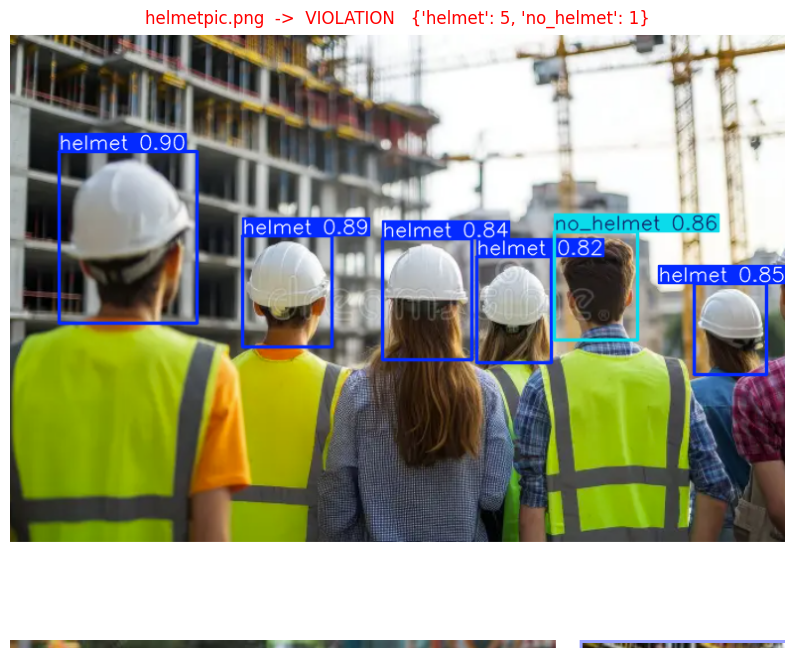

   helmet     confidence 0.90
   helmet     confidence 0.89
   no_helmet  confidence 0.86
   helmet     confidence 0.85
   helmet     confidence 0.84
   helmet     confidence 0.82


In [ ]:
# ===== TEST MY MODEL ON MY OWN PICTURES =====
from google.colab import drive, files
drive.mount("/content/drive")
!pip install -q ultralytics

from ultralytics import YOLO
from collections import Counter
from pathlib import Path
import matplotlib.pyplot as plt, cv2

model = YOLO("/content/drive/MyDrive/cv_project/models/best.pt")
CONF = 0.35          # lower = finds more objects, higher = only very sure ones

save_dir = Path("/content/drive/MyDrive/cv_project/outputs/my_tests")
save_dir.mkdir(parents=True, exist_ok=True)

uploaded = files.upload()          # a "Choose Files" button appears - pick one or many photos

for name in uploaded:
    r = model.predict(name, conf=CONF, verbose=False)[0]
    counts = Counter(r.names[int(c)] for c in r.boxes.cls.tolist())
    status = ("VIOLATION" if counts.get("no_helmet")
              else "COMPLIANT" if counts.get("helmet") else "NO HEADS DETECTED")
    plt.figure(figsize=(10, 8)); plt.imshow(r.plot()[:, :, ::-1]); plt.axis("off")
    plt.title(f"{name}  ->  {status}   {dict(counts)}",
              color="red" if status == "VIOLATION" else "green")
    plt.show()
    for c, s in zip(r.boxes.cls.tolist(), r.boxes.conf.tolist()):
        print(f"   {r.names[int(c)]:<10} confidence {s:.2f}")
    cv2.imwrite(str(save_dir / f"result_{name}"), r.plot())   # saved to Drive

In [1]:
# ===== GRADIO DEMO (works in a fresh session) =====
from google.colab import drive
drive.mount("/content/drive")
!pip install -q ultralytics gradio

from ultralytics import YOLO
from collections import Counter
import gradio as gr

model = YOLO("/content/drive/MyDrive/cv_project/models/best.pt")
CLASSES = ["helmet", "no_helmet", "person"]

def detect(image, conf):
    if image is None:
        return None, "Upload an image first", {}
    r = model.predict(image, conf=conf, verbose=False)[0]
    cnt = Counter(r.names[int(c)] for c in r.boxes.cls.tolist())
    if cnt.get("no_helmet", 0):
        status = f"🚨 VIOLATION - {cnt['no_helmet']} worker(s) without a helmet"
    elif cnt.get("helmet", 0):
        status = "✅ COMPLIANT - every detected head wears a helmet"
    else:
        status = "ℹ️ No heads detected"
    return r.plot()[:, :, ::-1], status, {c: cnt.get(c, 0) for c in CLASSES}

gr.Interface(
    fn=detect,
    inputs=[gr.Image(type="numpy", label="Upload a worksite image"),
            gr.Slider(0.1, 0.9, value=0.35, step=0.05, label="Confidence threshold")],
    outputs=[gr.Image(label="Detections"), gr.Textbox(label="Safety status"), gr.JSON(label="Counts")],
    title="🦺 Safety Helmet Detection (YOLOv8)",
).launch(share=True)

Mounted at /content/drive
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 3.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 33.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 8.2 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://acdc53b7632ea71357.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
